In [3]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde
import csv
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
from time import perf_counter
from matplotlib.patches import Circle, FancyArrowPatch
from skimage import morphology, measure
try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({
    'font.size': 20,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'figure.titlesize': 25
})

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import (k_to_mask_length, iterative_filtering1D,
                              iterative_filtering1DWithKCutOff, iterative_filtering3D)
from shared.detection import detect_current_sheets
from shared.thickness import gaussian
from shared.stats import bootstrap_lognorm_median
from shared.loading import load
from shared.paths import DATA_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [4]:
#Defining all the required functions

#Fourier Transform Functions



#Defining constants
dx = 0.0625
dy = 0.0625






In [ ]:
# Standalone check: one snapshot through the 1D iterative filter (the pipeline cells below read their own data)
BETA, TIME = 1, 200                        # beta_p (beta_e = 1) and snapshot, as in the pipeline cells
run_path = f"{DATA_ROOT}/beta_p_{BETA}/beta_e_1"
data_Bx, data_By, data_Bz = (load(c, TIME, run_path) for c in ("Bx", "By", "Bz"))

data_Bx_filtered = iterative_filtering1D(data_Bx, 1)
data_By_filtered = iterative_filtering1D(data_By, 1)
data_Bz_filtered = iterative_filtering1D(data_Bz, 1)

Extracting 50 (beta,time) combos across 50 fork workers (1 thread(s) each)  [VISUALS ON] ...
IMFIMF  11

IMF 1
IMF 1
IMF 1
IMFIMF  11

IMF 1IMF
 1
IMF 1IMF
 1
IMF 1IMF
 1
IMF 1
IMF 1
IMF 1
IMFIMFIMF   111IMF


 IMF1
 1
IMF 1
IMFIMF  11

IMF 1IMFIMF
 1 
1
IMF 1
IMFIMFIMF   1IMF1

 11

IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMF 1
IMFIMF IMF 11 

1
IMF 1
IMF 1
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMFIMF  2
2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMFIMFIMF   22
2

IMF 2
IMF 2
IMF 2
IMFIMF  22

IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 3
IMF 3
IMF 2
IMF 2
IMF 2
IMF 3
IMF 3
IMFIMF  32

IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 2
IMF 3
IMF 3
IMF 2
IMF 2
IMF 2
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 4
IMF 4
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 4
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 3
IMF 4
IMF 3
IMF 4
IMF 3
IMF 3
IMF 3
IMF 3
IMF 4
IMF 3
IMF 3
IMF 4
IMF 4
IMF 4
IMF 4
IMF 4
IMF 4
IMF 4
IMF 4
IMF 4
IMF 4
I

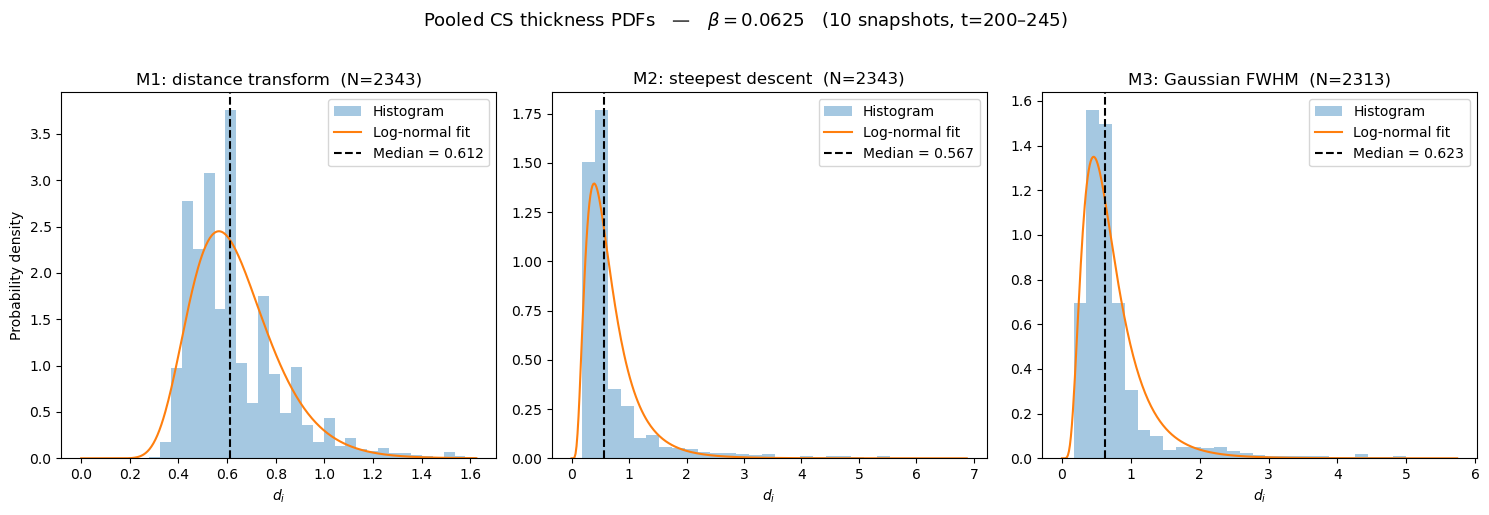

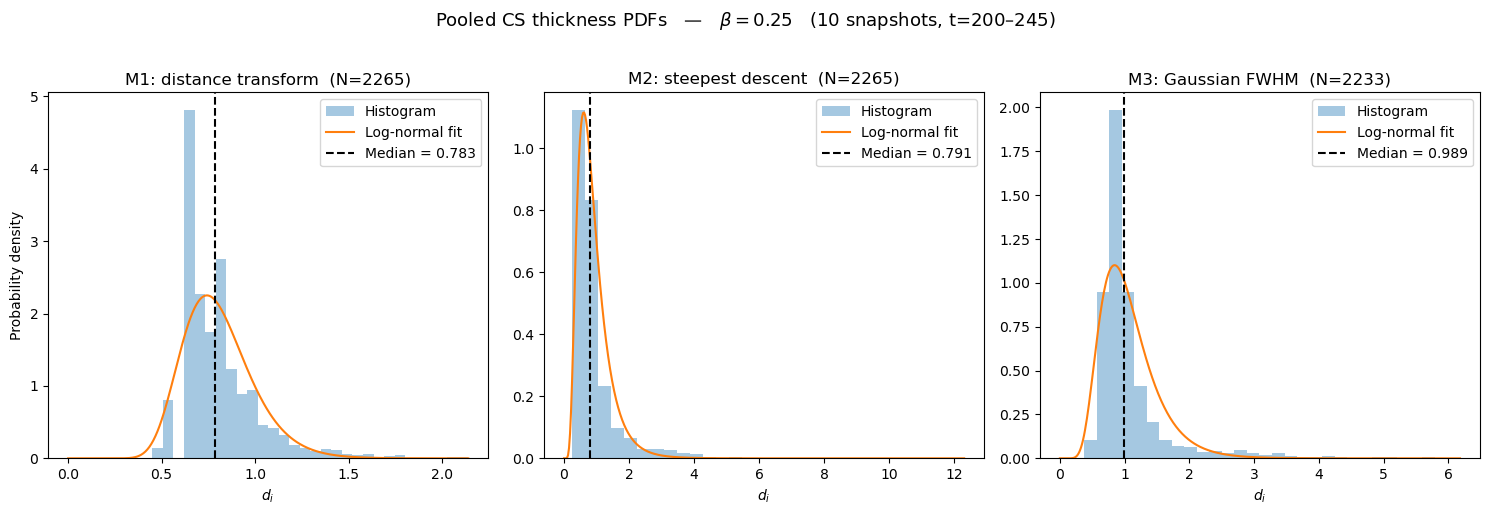

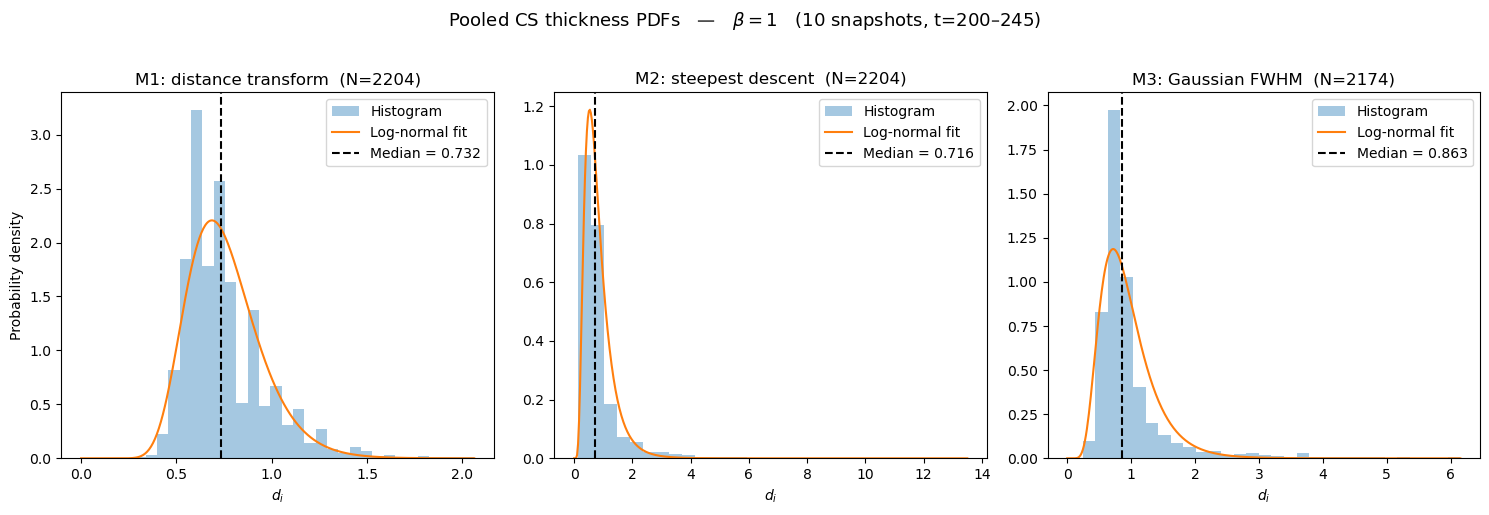

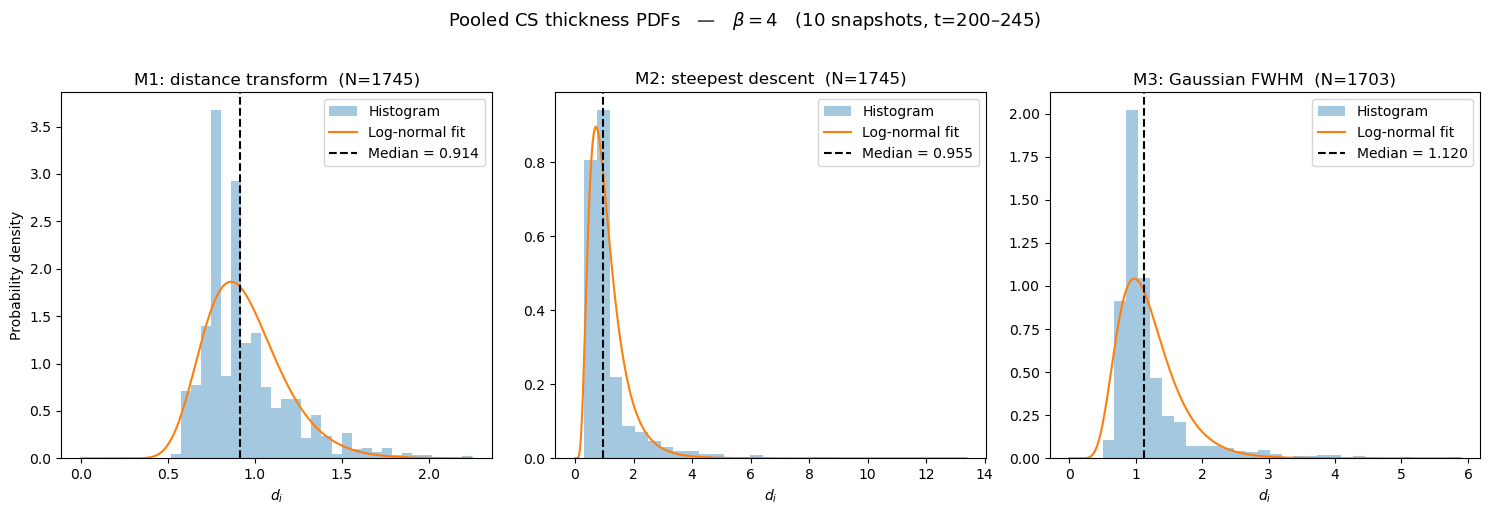

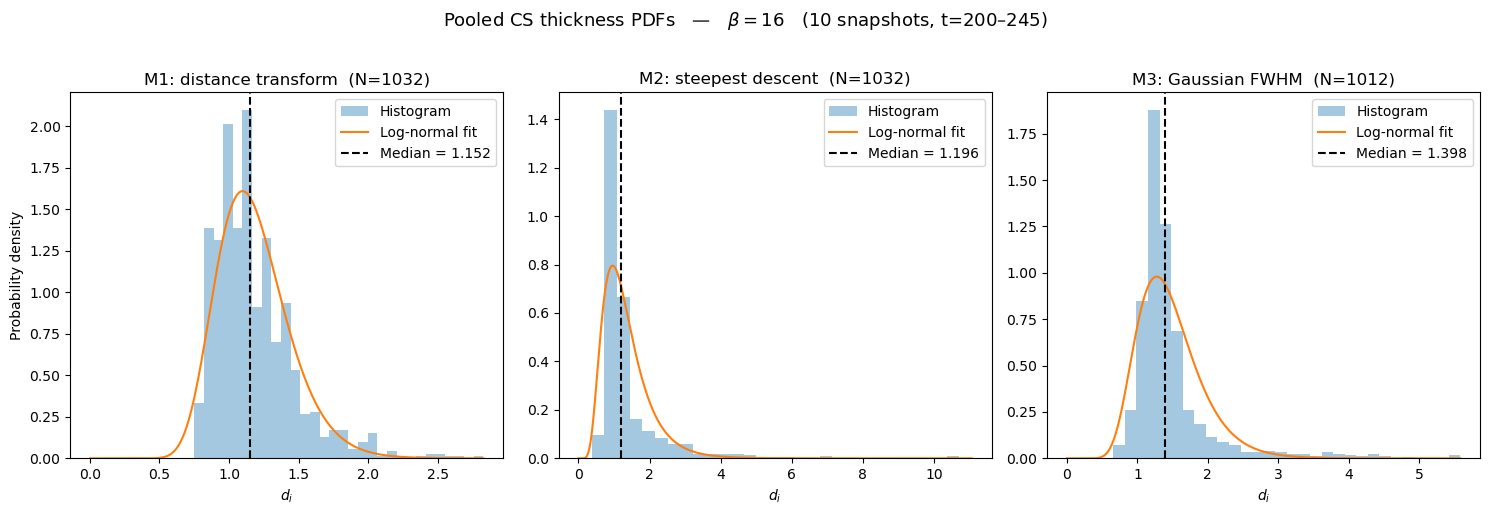

In [11]:
# =====================================================================
# Pool current-sheet thickness over MANY snapshots into one dataset per beta,
# with an OPTIONAL per-sheet visual-diagnostics mode.
#
# Default (SAVE_SHEET_VISUALS = False): for each beta, extract per-sheet
# thicknesses (M1/M2/M3) from every snapshot in TIMES, pool them, fit a
# lognormal, bootstrap the median, and save:
#     OUT_ROOT/beta_<beta>/pdf_pooled_beta<beta>.png
#     OUT_ROOT/beta_<beta>/pooled_thicknesses_beta<beta>.npz
#     OUT_ROOT/pooled_summary.csv
#
# With SAVE_SHEET_VISUALS = True, extraction ALSO writes, per snapshot:
#     OUT_ROOT/beta_<beta>/sheets_t<time>/overview.png   (field, sheets numbered)
#     OUT_ROOT/beta_<beta>/sheets_t<time>/sheet_<k>.png  (crop + M1/M2/M3 drawn,
#                                                          plus the M3 profile+fit)
#
# Uses ONE consistent labeling (CONNECTIVITY) for all three methods, so each
# sheet's M1/M2/M3 are the same region. (Production used scipy 4-conn for M2/M3
# vs skimage 8-conn for M1 -- a likely source of inconsistent statistics.)
#
# Parallel over (beta, time). Set N_WORKERS = 1 for a serial, verbose run.
# Must already exist in your session:
#   iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets, dx, dy
# =====================================================================

# -----------------------------
# USER SETTINGS
# -----------------------------
BETAS = [0.0625, 0.25, 1, 4, 16]
TIMES = list(range(200, 250, 5))          # 40, 45, ..., 90  -> pooled per beta

OUT_ROOT  = str(RESULTS / "cs_thickness_pooled_1")
cache_dir = str(CACHE / "filtered_cache_Jz")
PX_PER_DI = 16.0
N_WORKERS = min(len(BETAS) * len(TIMES), os.cpu_count() or 1)
N_BOOTSTRAP = 1000
THREADS_PER_WORKER = 1

# ---- debug visuals ----
SAVE_SHEET_VISUALS = True              # <<< turn ON to also dump per-sheet cards
CONNECTIVITY = 2                        # 2 = 8-connectivity (used for ALL methods)
MAX_SHEETS_VIS = None                   # cap cards per snapshot (None = all); e.g. 25
PAD = 20                                # crop padding around each sheet (px)

# filtering keyed by BETA (same setting for every pooled snapshot)
FILTER_PARAMS_BETA = {
    0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0),
}

# M3 sampling parameters
max_len      = 60
subpix_step  = 0.5
margin_frac  = 0.5
min_half     = 6.0
smooth_sigma = 3

os.makedirs(OUT_ROOT, exist_ok=True)
os.makedirs(cache_dir, exist_ok=True)


# -----------------------------
# Helpers
# -----------------------------
def log(msg):
    print(msg, flush=True)


_WORKER_TL = None


def _init_worker(n_threads):
    global _WORKER_TL
    if threadpool_limits is not None:
        _WORKER_TL = threadpool_limits(limits=n_threads)




def filter_params(beta):
    try:
        return FILTER_PARAMS_BETA[beta]
    except KeyError:
        raise KeyError(f"no filter params for beta={beta}; add it to FILTER_PARAMS_BETA")


def _walk_m2(mask, x0, y0, dx_, dy_, step=1, max_steps=1000):
    """Production M2 walk (edge-stop). Returns (distance, endpoint)."""
    nx, ny = mask.shape
    xf, yf, s = float(x0), float(y0), 0
    while s < max_steps:
        xn, yn = xf + dx_ * step, yf + dy_ * step
        xi, yi = int(round(xn)), int(round(yn))
        if xi < 0 or yi < 0 or xi >= nx or yi >= ny:
            break
        if not mask[xi, yi]:
            break
        xf, yf, s = xn, yn, s + 1
    return np.hypot(xf - x0, yf - y0), (xf, yf)


def _m3_profile_and_fit(J2, mask, xm, ym, dx_, dy_):
    """Returns (xs, vals, popt, fwhm, mu) for the Gaussian-FWHM measurement."""
    if dx_ == 0 and dy_ == 0:
        return None, None, None, np.nan, np.nan
    nx, ny = mask.shape

    def edge(sx, sy):
        d = 0.0
        while d < max_len:
            dn = d + subpix_step
            xi, yi = int(round(xm + sx * dn)) % nx, int(round(ym + sy * dn)) % ny
            if not mask[xi, yi]:
                break
            d = dn
        return d
    half_f = min(max_len, max(min_half, edge(dx_, dy_) * (1 + margin_frac)))
    half_b = min(max_len, max(min_half, edge(-dx_, -dy_) * (1 + margin_frac)))
    xs = np.arange(-half_b, half_f + subpix_step, subpix_step)
    vals = ndi.map_coordinates(J2, np.vstack([xm + xs * dx_, ym + xs * dy_]),
                               order=1, mode="grid-wrap")
    if len(vals) < 4:
        return xs, vals, None, np.nan, np.nan
    B0, A0 = float(vals.min()), float(vals.max() - vals.min())
    if A0 <= 0:
        return xs, vals, None, np.nan, np.nan
    mu0 = float(xs[np.argmax(vals)])
    above = np.where(vals >= B0 + 0.5 * A0)[0]
    sigma0 = (max(1.0, (xs[above[-1]] - xs[above[0]]) / 2.3548)
              if above.size >= 2 else max(2.0, (half_f + half_b) / 6.0))
    span = float(xs.max() - xs.min())
    sigma0 = min(sigma0, 0.99 * span)
    bounds = ([0.0, xs.min() - 1, 1e-3, -np.inf], [np.inf, xs.max() + 1, span, np.inf])
    try:
        popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0],
                            bounds=bounds, maxfev=10000)
        return xs, vals, popt, 2 * np.sqrt(2 * np.log(2)) * abs(popt[2]), popt[1]
    except (RuntimeError, ValueError):
        return xs, vals, None, np.nan, np.nan




def fit_and_plot_pdf(ax, x_di, title, bins=30, ylabel=False):
    x = np.asarray(x_di, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]
    ax.set_xlabel(r"$d_i$")
    if ylabel:
        ax.set_ylabel("Probability density")
    if x.size < 5:
        ax.set_title(f"{title}  (N={x.size})")
        ax.text(0.5, 0.5, "insufficient data", ha="center", va="center",
                transform=ax.transAxes, color="0.5")
        return {"n": int(x.size), "median_lognorm": np.nan, "sigma_lognorm": np.nan,
                "mean": np.nan, "median_emp": np.nan}
    shape, loc, scale = lognorm.fit(x, floc=0)
    xs_fit = np.linspace(0, x.max(), 400)
    ax.hist(x, bins=bins, density=True, alpha=0.4, label="Histogram")
    ax.plot(xs_fit, lognorm.pdf(xs_fit, shape, loc, scale), label="Log-normal fit")
    ax.axvline(scale, color="k", ls="--", lw=1.5, label=f"Median = {scale:.3f}")
    ax.set_title(f"{title}  (N={x.size})")
    ax.legend()
    return {"n": int(x.size), "median_lognorm": float(scale),
            "sigma_lognorm": float(shape), "mean": float(x.mean()),
            "median_emp": float(np.median(x))}


# -----------------------------
# Visual diagnostics (only used when SAVE_SHEET_VISUALS)
# -----------------------------
def _render_overview(J2, labeled, nreg, beta, time, visdir):
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(J2.T, origin="lower", cmap="inferno", vmax=float(np.percentile(J2, 99.5)))
    ax.contour(find_boundaries(labeled).T, levels=[0.5], colors="cyan", linewidths=0.4)
    for k in range(1, nreg + 1):
        xr, yr = np.where(labeled == k)
        ax.text(xr.mean(), yr.mean(), str(k), color="white", fontsize=6,
                ha="center", va="center")
    ax.set_title(f"beta={beta}, t={time}: {nreg} sheets")
    ax.set_xlabel(r"$x/d_p$"); ax.set_ylabel(r"$y/d_p$")
    fig.savefig(os.path.join(visdir, "overview.png"), dpi=200, bbox_inches="tight")
    plt.close(fig)


def _render_card(visdir, beta, time, k, J2, labeled, g):
    """g: dict of per-sheet geometry/measurements."""
    xs_r, ys_r = np.where(labeled == k)
    Nx, Ny = J2.shape
    x0, x1 = max(0, xs_r.min() - PAD), min(Nx, xs_r.max() + PAD + 1)
    y0, y1 = max(0, ys_r.min() - PAD), min(Ny, ys_r.max() + PAD + 1)
    crop = J2[x0:x1, y0:y1]
    regcrop = (labeled[x0:x1, y0:y1] == k)
    ext = [x0, x1, y0, y1]
    xm, ym, dx_, dy_ = g["xm"], g["ym"], g["dx"], g["dy"]

    fig, (axL, axR) = plt.subplots(1, 2, figsize=(11, 5))
    axL.imshow(crop.T, origin="lower", extent=ext, cmap="inferno",
               vmax=float(np.percentile(crop, 99.5)), aspect="equal")
    axL.contour(regcrop.T, levels=[0.5], colors="white", linewidths=1.0, extent=ext)
    axL.plot(xm, ym, "x", color="yellow", ms=11, mew=2, label="max", zorder=6)
    axL.add_patch(Circle((g["epx"], g["epy"]), g["r1"], fill=False, ec="cyan", lw=1.6,
                         label=f"M1 = {g['m1']/PX_PER_DI:.2f}"))
    (xf, yf), (xb, yb) = g["fwd"], g["bwd"]
    axL.plot([xb, xf], [yb, yf], "-", color="lime", lw=2.2,
             label=f"M2 = {g['m2']/PX_PER_DI:.2f}", zorder=5)
    if np.isfinite(g["fwhm"]) and (dx_ or dy_):
        cx, cy = xm + g["mu"] * dx_, ym + g["mu"] * dy_
        ex, ey = (g["fwhm"] / 2) * dx_, (g["fwhm"] / 2) * dy_
        axL.plot([cx - ex, cx + ex], [cy - ey, cy + ey], "-", color="magenta",
                 lw=2.2, label=f"M3 = {g['fwhm']/PX_PER_DI:.2f}", zorder=5)
    if dx_ or dy_:
        axL.add_patch(FancyArrowPatch((xm, ym), (xm + 8 * dx_, ym + 8 * dy_),
                      arrowstyle="->", color="white", mutation_scale=12, lw=1, zorder=6))
    axL.set_xlim(x0, x1); axL.set_ylim(y0, y1)
    axL.set_xlabel(r"$x/d_p$"); axL.set_ylabel(r"$y/d_p$")
    axL.set_title(f"sheet {k}")
    axL.legend(fontsize=7, loc="upper right", framealpha=0.6)

    xs_p, vals_p, popt = g["xs"], g["vals"], g["popt"]
    if xs_p is not None and len(xs_p) > 0:
        axR.plot(xs_p, vals_p, "o", ms=3, color="0.3", label="J2 profile")
        if popt is not None:
            A, muf, sig, B = popt
            xd = np.linspace(xs_p.min(), xs_p.max(), 400)
            axR.plot(xd, gaussian(xd, A, muf, sig, B), "-", color="magenta", label="Gaussian fit")
            axR.axhline(B + A / 2, color="0.6", ls=":", lw=1, label="half-max")
        axR.set_xlabel("distance along descent (px)"); axR.set_ylabel(r"$J^2$ ($|J_z|$)")
        axR.legend(fontsize=8)
    else:
        axR.text(0.5, 0.5, "no profile (flat gradient)", ha="center", va="center",
                 transform=axR.transAxes, color="0.5")

    fig.suptitle(f"beta={beta}, t={time}, sheet {k}   |   "
                 f"M1={g['m1']/PX_PER_DI:.2f}  M2={g['m2']/PX_PER_DI:.2f}  "
                 f"M3={g['fwhm']/PX_PER_DI:.2f}  d_i", fontsize=11)
    fig.tight_layout()
    fig.savefig(os.path.join(visdir, f"sheet_{k:03d}.png"), dpi=130, bbox_inches="tight")
    plt.close(fig)


# -----------------------------
# Per-(beta, time) thickness extraction (+ optional visuals)
# -----------------------------
def extract_thicknesses(beta, time, verbose=False):
    if SAVE_SHEET_VISUALS and mp.parent_process() is not None:
        plt.switch_backend("Agg")
    _log = log if verbose else (lambda *a, **k: None)
    t0 = perf_counter()
    n_iter, Xi = filter_params(beta)
    base_path = f"{DATA_ROOT}/beta_p_{beta}/beta_e_1/"

    _log(f"  loading beta={beta}, t={time} ...")
    with h5py.File(base_path + f"Bx_ApJ_t{time}.h5", "r") as fBx, \
         h5py.File(base_path + f"By_ApJ_t{time}.h5", "r") as fBy, \
         h5py.File(base_path + f"Bz_ApJ_t{time}.h5", "r") as fBz:
        data_Bx = fBx["DS1"][:].T
        data_By = fBy["DS1"][:].T
        data_Bz = fBz["DS1"][:].T

    cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    cached = os.path.exists(cache_file)
    if cached:
        d = np.load(cache_file)
        data_Bx_f, data_By_f, data_Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        _log(f"  filtering beta={beta}, t={time} (MIF) ...")
        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f)

    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    cleaned_mask = morphology.remove_small_objects(
        mask.astype(bool), min_size=500).astype(int)

    # ONE consistent labeling for all three methods
    labeled = measure.label(cleaned_mask, connectivity=CONNECTIVITY)
    nreg = int(labeled.max())

    J2_smooth = gaussian_filter(J2, sigma=smooth_sigma)
    gx, gy = np.gradient(J2_smooth)

    visdir = None
    if SAVE_SHEET_VISUALS:
        visdir = os.path.join(OUT_ROOT, f"beta_{beta}", f"sheets_t{time}")
        os.makedirs(visdir, exist_ok=True)
        _render_overview(J2, labeled, nreg, beta, time, visdir)

    m1_list, m2_list, m3_list = [], [], []
    nvis = 0
    for k in range(1, nreg + 1):
        region = (labeled == k)
        xs_r, ys_r = np.where(region)
        rv = J2[region]
        p = int(np.argmax(rv))
        xm, ym = int(xs_r[p]), int(ys_r[p])

        # M1: inscribed circle from EDT
        edt = ndi.distance_transform_edt(region)
        r1 = float(edt.max()); m1 = 2 * r1
        epx, epy = np.unravel_index(int(np.argmax(edt)), edt.shape)

        # descent direction
        gvec = np.array([gx[xm, ym], gy[xm, ym]])
        if np.allclose(gvec, 0):
            dx_, dy_ = 0.0, 0.0
        else:
            v = -gvec / np.linalg.norm(gvec); dx_, dy_ = float(v[0]), float(v[1])

        # M2: walk to mask edges along descent
        df, fwd = _walk_m2(cleaned_mask, xm, ym, dx_, dy_)
        db, bwd = _walk_m2(cleaned_mask, xm, ym, -dx_, -dy_)
        m2 = df + db

        # M3: Gaussian FWHM along descent
        xs_p, vals_p, popt, fwhm, mu = _m3_profile_and_fit(J2, cleaned_mask, xm, ym, dx_, dy_)

        m1_list.append(m1)
        m2_list.append(m2)
        m3_list.append(fwhm)

        if SAVE_SHEET_VISUALS and (MAX_SHEETS_VIS is None or nvis < MAX_SHEETS_VIS):
            _render_card(visdir, beta, time, k, J2, labeled,
                         {"xm": xm, "ym": ym, "dx": dx_, "dy": dy_,
                          "m1": m1, "epx": epx, "epy": epy, "r1": r1,
                          "m2": m2, "fwd": fwd, "bwd": bwd,
                          "fwhm": fwhm, "mu": mu, "xs": xs_p, "vals": vals_p, "popt": popt})
            nvis += 1

    # returned arrays for pooling (same filters as before)
    m1 = np.array(m1_list, dtype=float)
    m2 = np.array(m2_list, dtype=float); m2 = m2[m2 > 0]
    m3 = np.array(m3_list, dtype=float); m3 = m3[np.isfinite(m3)]; m3 = m3[(m3 > 0) & (m3 <= 100)]

    return {"beta": beta, "time": time, "m1": m1, "m2": m2, "m3": m3,
            "n_sheets": nreg, "cached": cached, "elapsed": perf_counter() - t0}


# -----------------------------
# Dispatch extraction (parallel) -> pool per beta -> fit / bootstrap / plot
# -----------------------------
combos = [(b, t) for b in BETAS for t in TIMES]
ncombo = len(combos)
results = []

if N_WORKERS == 1:
    for k, (b, t) in enumerate(combos, 1):
        try:
            r = extract_thicknesses(b, t, verbose=True)
            results.append(r)
            log(f"[{k}/{ncombo}] beta={b}, t={t} "
                f"(M1={r['m1'].size}, M2={r['m2'].size}, M3={r['m3'].size}, {r['elapsed']:.1f}s)")
        except FileNotFoundError:
            log(f"[{k}/{ncombo}] SKIP beta={b}, t={t}: missing file")
        except Exception as e:
            log(f"[{k}/{ncombo}] FAIL beta={b}, t={t}: {type(e).__name__}: {e}")
else:
    ctx = mp.get_context("fork")
    if threadpool_limits is None:
        log("note: threadpoolctl not found -> workers may oversubscribe BLAS/FFT threads. "
            "`pip install threadpoolctl` for best utilisation.")
    log(f"Extracting {ncombo} (beta,time) combos across {N_WORKERS} fork workers "
        f"({THREADS_PER_WORKER} thread(s) each)"
        + ("  [VISUALS ON]" if SAVE_SHEET_VISUALS else "") + " ...")
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                             initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
        futs = {ex.submit(extract_thicknesses, b, t, False): (b, t) for b, t in combos}
        done = 0
        for fut in as_completed(futs):
            b, t = futs[fut]; done += 1
            try:
                r = fut.result()
                results.append(r)
                src = "cached" if r["cached"] else "filtered"
                log(f"[{done}/{ncombo}] beta={b}, t={t}  "
                    f"(M1={r['m1'].size}, M2={r['m2'].size}, M3={r['m3'].size}, {src}, {r['elapsed']:.1f}s)")
            except FileNotFoundError:
                log(f"[{done}/{ncombo}] SKIP beta={b}, t={t}: missing file")
            except Exception as e:
                log(f"[{done}/{ncombo}] FAIL beta={b}, t={t}: {type(e).__name__}: {e}")

# ----- pool per beta, fit, bootstrap, plot, save -----
rng = np.random.default_rng(0)
summary_rows = []
panel_spec = [("m1", "M1: distance transform", True),
              ("m2", "M2: steepest descent", False),
              ("m3", "M3: Gaussian FWHM", False)]

for b in BETAS:
    rs = [r for r in results if r["beta"] == b]
    if not rs:
        log(f"beta={b}: no snapshots succeeded, skipping")
        continue
    times_done = sorted(r["time"] for r in rs)
    pooled_di = {m: np.concatenate([r[m] for r in rs]) / PX_PER_DI for m, _, _ in panel_spec}

    outdir = os.path.join(OUT_ROOT, f"beta_{b}")
    os.makedirs(outdir, exist_ok=True)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (m, name, yl) in zip(axes, panel_spec):
        st = fit_and_plot_pdf(ax, pooled_di[m], name, ylabel=yl)
        se, lo, hi = bootstrap_lognorm_median(pooled_di[m], N_BOOTSTRAP, rng)
        summary_rows.append({
            "beta": b, "method": name.split(":")[0],
            "n_snapshots": len(times_done), "n_sheets_pooled": st["n"],
            "median_lognorm_di": st["median_lognorm"], "sigma_lognorm": st["sigma_lognorm"],
            "median_se_di": se, "ci_lo_di": lo, "ci_hi_di": hi,
            "mean_di": st["mean"], "median_emp_di": st["median_emp"],
        })
    fig.suptitle(rf"Pooled CS thickness PDFs   —   $\beta = {b}$   "
                 rf"({len(times_done)} snapshots, t={times_done[0]}–{times_done[-1]})",
                 y=1.02, fontsize=13)
    fig.tight_layout()
    figpath = os.path.join(outdir, f"pdf_pooled_beta{b}.png")
    fig.savefig(figpath, dpi=300, bbox_inches="tight")

    np.savez_compressed(os.path.join(outdir, f"pooled_thicknesses_beta{b}.npz"),
                        times=np.array(times_done),
                        m1_di=pooled_di["m1"], m2_di=pooled_di["m2"], m3_di=pooled_di["m3"])
    log(f"beta={b}: pooled {len(times_done)} snapshots "
        f"(M1={pooled_di['m1'].size}, M2={pooled_di['m2'].size}, M3={pooled_di['m3'].size}) -> {figpath}")

# ----- summary CSV -----
summary_rows.sort(key=lambda r: (r["beta"], r["method"]))
csv_path = os.path.join(OUT_ROOT, "pooled_summary.csv")
with open(csv_path, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["beta", "method", "n_snapshots", "n_sheets_pooled",
                                      "median_lognorm_di", "sigma_lognorm",
                                      "median_se_di", "ci_lo_di", "ci_hi_di",
                                      "mean_di", "median_emp_di"])
    w.writeheader()
    w.writerows(summary_rows)

log(f"\nDone. {len(summary_rows)} rows -> {csv_path}")
log(f"Pooled figures + .npz under {OUT_ROOT}/beta_<beta>/"
    + ("  (+ per-sheet cards in sheets_t<time>/)" if SAVE_SHEET_VISUALS else ""))

Extracting 10 snapshots across 10 workers ...
t=245: M1=197 M2=197 M3=196
t=220: M1=208 M2=208 M3=206
t=235: M1=206 M2=206 M3=204
t=230: M1=212 M2=212 M3=210
t=225: M1=215 M2=215 M3=211
t=240: M1=214 M2=214 M3=213
t=215: M1=231 M2=231 M3=228
t=210: M1=235 M2=235 M3=230
t=205: M1=242 M2=242 M3=236
t=200: M1=244 M2=244 M3=240
saved thickness_methods_comparison_beta1.png
saved pooled_thicknesses_beta1.npz

method   median(d_i)   sigma       N
M1             0.732   0.255    2204
M2             0.716   0.543    2204
M3             0.863   0.427    2174


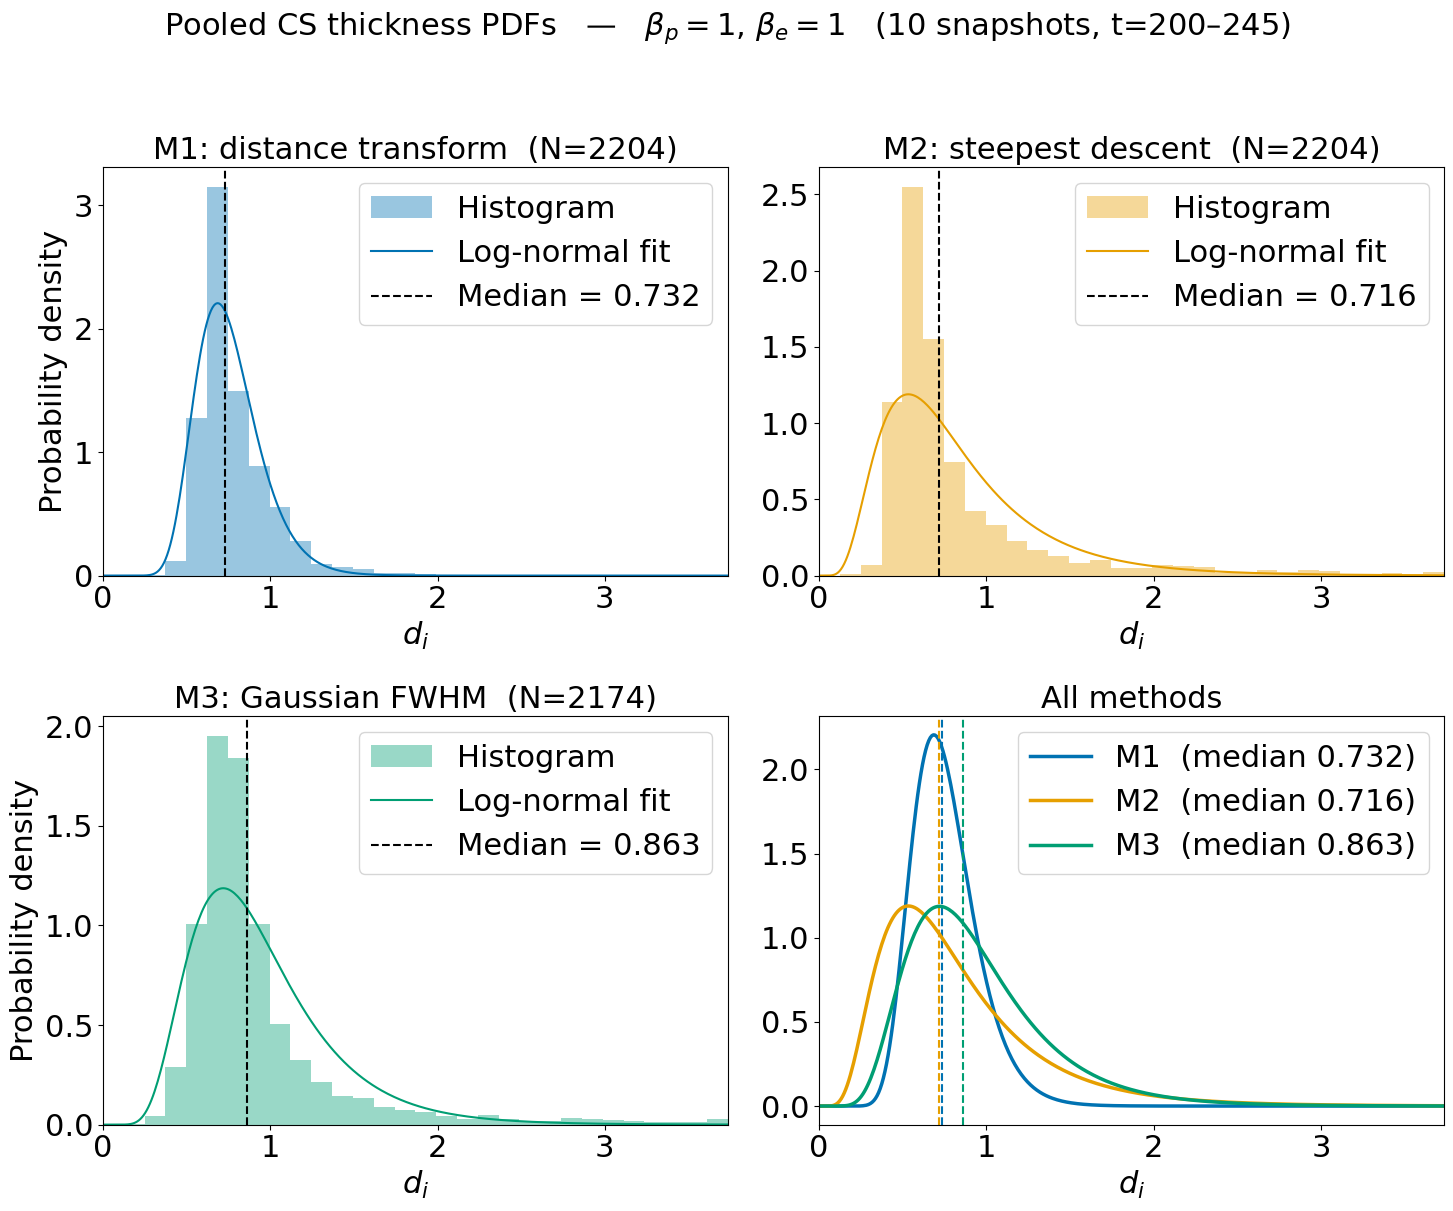

In [5]:
# =====================================================================
# ONE figure (2x2): pooled current-sheet thickness PDFs for beta_p = 1, beta_e = 1,
# comparing the three thickness methods (M1/M2/M3).
#
#   [0,0] M1 : histogram + lognormal fit + median      (original formatting)
#   [0,1] M2 : histogram + lognormal fit + median
#   [1,0] M3 : histogram + lognormal fit + median
#   [1,1] all three lognormal fits overlaid, with medians
#
# All four panels share the SAME x-axis extent. Each method keeps its own colour
# (reused across panels). Thicknesses are pooled over TIMES (10 snapshots).
# No per-sheet / detection visuals.
#
# ONE consistent labeling (CONNECTIVITY = 8-conn) for all three methods.
#
# Must already exist in your session:
#   iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets
# =====================================================================

import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
from scipy.stats import lognorm
from time import perf_counter
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

# -----------------------------
# FONTS (22 everywhere)
# -----------------------------
plt.rcParams.update({
    'font.size': 22,
    'axes.titlesize': 22,
    'axes.labelsize': 22,
    'xtick.labelsize': 22,
    'ytick.labelsize': 22,
    'legend.fontsize': 22,
    'figure.titlesize': 22,
})

# -----------------------------
# USER SETTINGS
# -----------------------------
BETA      = 1                              # beta_p = 1  (beta_e = 1 fixed)
TIMES     = list(range(200, 250, 5))       # 200, 205, ..., 245  -> 10 snapshots pooled
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)

cache_dir = str(CACHE / "filtered_cache_Jz")
out_fig   = str(RESULTS / "thickness_methods_comparison_beta1.png")
out_npz   = str(RESULTS / "pooled_thicknesses_beta1.npz")

PX_PER_DI    = 16.0
CONNECTIVITY = 2                           # 8-connectivity for ALL methods
N_WORKERS    = min(len(TIMES), os.cpu_count() or 1)
THREADS_PER_WORKER = 1
NBINS        = 30
XMAX_PCTILE  = 99                          # shared x-limit = this pctile of all pooled thicknesses
dx = dy      = 0.0625

# one distinct colour per method (colourblind-safe Okabe-Ito) -- reuse these in the talk
METHOD_COLORS = {"M1": "#0072B2",   # blue
                 "M2": "#E69F00",   # orange
                 "M3": "#009E73"}   # green

# filtering for beta_p = 1
FILTER_PARAMS_BETA = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

# M3 sampling parameters
max_len, subpix_step, margin_frac, min_half, smooth_sigma = 60, 0.5, 0.5, 6.0, 3

os.makedirs(cache_dir, exist_ok=True)


# -----------------------------
# Helpers
# -----------------------------
def _init_worker(n_threads):
    if threadpool_limits is not None:
        threadpool_limits(limits=n_threads)




def filter_params(beta):
    return FILTER_PARAMS_BETA[beta]


def _walk_m2(mask, x0, y0, dx_, dy_, step=1, max_steps=1000):
    nx, ny = mask.shape
    xf, yf, s = float(x0), float(y0), 0
    while s < max_steps:
        xn, yn = xf + dx_ * step, yf + dy_ * step
        xi, yi = int(round(xn)), int(round(yn))
        if xi < 0 or yi < 0 or xi >= nx or yi >= ny:
            break
        if not mask[xi, yi]:
            break
        xf, yf, s = xn, yn, s + 1
    return np.hypot(xf - x0, yf - y0)


def _m3_fwhm(J2, mask, xm, ym, dx_, dy_):
    if dx_ == 0 and dy_ == 0:
        return np.nan
    nx, ny = mask.shape

    def edge(sx, sy):
        d = 0.0
        while d < max_len:
            dn = d + subpix_step
            xi, yi = int(round(xm + sx * dn)) % nx, int(round(ym + sy * dn)) % ny
            if not mask[xi, yi]:
                break
            d = dn
        return d
    half_f = min(max_len, max(min_half, edge(dx_, dy_) * (1 + margin_frac)))
    half_b = min(max_len, max(min_half, edge(-dx_, -dy_) * (1 + margin_frac)))
    xs = np.arange(-half_b, half_f + subpix_step, subpix_step)
    vals = ndi.map_coordinates(J2, np.vstack([xm + xs * dx_, ym + xs * dy_]),
                               order=1, mode="grid-wrap")
    if len(vals) < 4:
        return np.nan
    B0, A0 = float(vals.min()), float(vals.max() - vals.min())
    if A0 <= 0:
        return np.nan
    mu0 = float(xs[np.argmax(vals)])
    above = np.where(vals >= B0 + 0.5 * A0)[0]
    sigma0 = (max(1.0, (xs[above[-1]] - xs[above[0]]) / 2.3548)
              if above.size >= 2 else max(2.0, (half_f + half_b) / 6.0))
    span = float(xs.max() - xs.min())
    sigma0 = min(sigma0, 0.99 * span)
    bounds = ([0.0, xs.min() - 1, 1e-3, -np.inf], [np.inf, xs.max() + 1, span, np.inf])
    try:
        popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0], bounds=bounds, maxfev=10000)
        return 2 * np.sqrt(2 * np.log(2)) * abs(popt[2])
    except (RuntimeError, ValueError):
        return np.nan


def fit_and_plot_pdf(ax, x_di, title, color, bins=30, ylabel=False, xmax=None):
    """Original per-method PDF panel: histogram + lognormal fit + median.
    Adds a per-method `color` (hist + fit) and a shared `xmax`; formatting is
    otherwise unchanged from the production version."""
    x = np.asarray(x_di, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]
    ax.set_xlabel(r"$d_i$")
    if ylabel:
        ax.set_ylabel("Probability density")
    if x.size < 5:
        ax.set_title(f"{title}  (N={x.size})")
        ax.text(0.5, 0.5, "insufficient data", ha="center", va="center",
                transform=ax.transAxes, color="0.5")
        if xmax is not None:
            ax.set_xlim(0, xmax)
        return {"n": int(x.size), "median_lognorm": np.nan, "sigma_lognorm": np.nan,
                "mean": np.nan, "median_emp": np.nan}
    shape, loc, scale = lognorm.fit(x, floc=0)
    xs_fit = np.linspace(0, xmax if xmax is not None else x.max(), 400)
    ax.hist(x, bins=bins, density=True, alpha=0.4, color=color, label="Histogram")
    ax.plot(xs_fit, lognorm.pdf(xs_fit, shape, loc, scale), color=color, label="Log-normal fit")
    ax.axvline(scale, color="k", ls="--", lw=1.5, label=f"Median = {scale:.3f}")
    ax.set_title(f"{title}  (N={x.size})")
    ax.legend()
    if xmax is not None:
        ax.set_xlim(0, xmax)
    return {"n": int(x.size), "median_lognorm": float(scale),
            "sigma_lognorm": float(shape), "mean": float(x.mean()),
            "median_emp": float(np.median(x))}


# -----------------------------
# One snapshot -> (time, m1_di, m2_di, m3_di)   (cache reused, no plotting)
# -----------------------------
def extract(time):
    n_iter, Xi = filter_params(BETA)
    base_path = f"{base_root}/beta_p_{BETA}/beta_e_1/"
    with h5py.File(base_path + f"Bx_{sim_tag}_t{time}.h5", "r") as fBx, \
         h5py.File(base_path + f"By_{sim_tag}_t{time}.h5", "r") as fBy, \
         h5py.File(base_path + f"Bz_{sim_tag}_t{time}.h5", "r") as fBz:
        data_Bx, data_By, data_Bz = fBx["DS1"][:].T, fBy["DS1"][:].T, fBz["DS1"][:].T

    cache_file = f"{cache_dir}/filtered_beta_{BETA}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        data_Bx_f, data_By_f, data_Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f)

    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    cleaned_mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)

    labeled = measure.label(cleaned_mask, connectivity=CONNECTIVITY)
    nreg = int(labeled.max())

    J2_smooth = gaussian_filter(J2, sigma=smooth_sigma)
    gx, gy = np.gradient(J2_smooth)

    m1_list, m2_list, m3_list = [], [], []
    for k in range(1, nreg + 1):
        region = (labeled == k)
        xs_r, ys_r = np.where(region)
        p = int(np.argmax(J2[region]))
        xm, ym = int(xs_r[p]), int(ys_r[p])

        edt = ndi.distance_transform_edt(region)
        m1_list.append(2 * float(edt.max()))

        gvec = np.array([gx[xm, ym], gy[xm, ym]])
        if np.allclose(gvec, 0):
            dx_, dy_ = 0.0, 0.0
        else:
            v = -gvec / np.linalg.norm(gvec); dx_, dy_ = float(v[0]), float(v[1])

        m2_list.append(_walk_m2(cleaned_mask, xm, ym, dx_, dy_)
                       + _walk_m2(cleaned_mask, xm, ym, -dx_, -dy_))
        m3_list.append(_m3_fwhm(J2, cleaned_mask, xm, ym, dx_, dy_))

    m1 = np.array(m1_list, float); m1 = m1[m1 > 0]
    m2 = np.array(m2_list, float); m2 = m2[m2 > 0]
    m3 = np.array(m3_list, float); m3 = m3[np.isfinite(m3)]; m3 = m3[(m3 > 0) & (m3 <= 100)]
    return time, m1 / PX_PER_DI, m2 / PX_PER_DI, m3 / PX_PER_DI


# -----------------------------
if __name__ == "__main__":
    # ---- extract all snapshots in parallel ----
    results = []
    if N_WORKERS == 1:
        for t in TIMES:
            try:
                r = extract(t); results.append(r)
                print(f"t={t}: M1={r[1].size} M2={r[2].size} M3={r[3].size}", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)
    else:
        ctx = mp.get_context("fork")
        if threadpool_limits is None:
            print("note: threadpoolctl not found -> workers may oversubscribe threads.", flush=True)
        print(f"Extracting {len(TIMES)} snapshots across {N_WORKERS} workers ...", flush=True)
        with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                                 initializer=_init_worker, initargs=(THREADS_PER_WORKER,)) as ex:
            futs = {ex.submit(extract, t): t for t in TIMES}
            for fut in as_completed(futs):
                t = futs[fut]
                try:
                    r = fut.result(); results.append(r)
                    print(f"t={t}: M1={r[1].size} M2={r[2].size} M3={r[3].size}", flush=True)
                except FileNotFoundError:
                    print(f"t={t}: missing file, skipped", flush=True)

    if not results:
        raise SystemExit("No snapshots extracted (check paths / TIMES).")
    results.sort(key=lambda r: r[0])
    times_done = [r[0] for r in results]

    # ---- pool per method ----
    pooled = {"M1": np.concatenate([r[1] for r in results]),
              "M2": np.concatenate([r[2] for r in results]),
              "M3": np.concatenate([r[3] for r in results])}

    # ---- shared x-axis (same extent for every panel) ----
    all_thick = np.concatenate([pooled[m] for m in ("M1", "M2", "M3")])
    all_thick = all_thick[np.isfinite(all_thick) & (all_thick > 0)]
    xmax   = float(np.percentile(all_thick, XMAX_PCTILE))
    bins   = np.linspace(0, xmax, NBINS + 1)
    xs_fit = np.linspace(0, xmax, 400)

    # ---- 2x2 figure ----
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    panel_axes = {"M1": axes[0, 0], "M2": axes[0, 1], "M3": axes[1, 0]}
    ax_cmp = axes[1, 1]
    # (title, ylabel) -- ylabel on the left column (M1 top-left, M3 bottom-left)
    panel_spec = [("M1", "M1: distance transform", True),
                  ("M2", "M2: steepest descent", False),
                  ("M3", "M3: Gaussian FWHM", True)]

    stats = {}
    for m, title, yl in panel_spec:
        stats[m] = fit_and_plot_pdf(panel_axes[m], pooled[m], title, METHOD_COLORS[m],
                                    bins=bins, ylabel=yl, xmax=xmax)

    # ---- comparison panel: all three lognormal fits + medians ----
    for m, title, yl in panel_spec:
        st = stats[m]; shape, scale = st["sigma_lognorm"], st["median_lognorm"]
        if np.isfinite(scale) and np.isfinite(shape):
            ax_cmp.plot(xs_fit, lognorm.pdf(xs_fit, shape, 0, scale),
                        color=METHOD_COLORS[m], lw=2.5, label=f"{m}  (median {scale:.3f})")
            ax_cmp.axvline(scale, color=METHOD_COLORS[m], ls="--", lw=1.5)
    ax_cmp.set_xlim(0, xmax)
    ax_cmp.set_xlabel(r"$d_i$")
    ax_cmp.set_title("All methods")
    ax_cmp.legend()

    fig.suptitle(rf"Pooled CS thickness PDFs   —   $\beta_p = {BETA}$, $\beta_e = 1$   "
                 rf"({len(times_done)} snapshots, t={times_done[0]}–{times_done[-1]})", y=1.02)
    fig.tight_layout()
    fig.savefig(out_fig, dpi=300, bbox_inches="tight")
    print(f"saved {out_fig}", flush=True)

    # ---- pooled data + printed summary ----
    np.savez_compressed(out_npz, times=np.array(times_done),
                        m1_di=pooled["M1"], m2_di=pooled["M2"], m3_di=pooled["M3"])
    print(f"saved {out_npz}", flush=True)
    print(f"\n{'method':7s} {'median(d_i)':>12s} {'sigma':>7s} {'N':>7s}")
    for m in ("M1", "M2", "M3"):
        st = stats[m]
        if np.isfinite(st["median_lognorm"]):
            print(f"{m:7s} {st['median_lognorm']:12.3f} {st['sigma_lognorm']:7.3f} {st['n']:7d}")
        else:
            print(f"{m:7s} {'--':>12s} {'--':>7s} {st['n']:7d}")

Extracting 10 snapshots across 10 workers ...
t=245: 197 sheets
t=235: 206 sheets
t=220: 208 sheets
t=230: 212 sheets
t=240: 214 sheets
t=225: 215 sheets
t=210: 235 sheets
t=215: 231 sheets
t=205: 242 sheets
t=200: 244 sheets

pooled 2204 sheets from 10 snapshots
saved thickness_log_gaussian_beta1.png
saved pooled_thickness_m1_beta1.npz

--- Gaussian fit to ln(thickness), N = 2204 ---
  mu     = -0.3119      -> median = exp(mu) = 0.7321 d_i
  sigma  = 0.2552   (the log-normal shape parameter)
  SE(mu) = 0.00544, SE(sigma) = 0.00384

  empirical median = 0.7071 d_i (fitted/empirical = 1.035; 1.000 if log-normal)
  skew(ln x)            = +0.711   (0 if Gaussian)
  excess kurtosis(ln x) = +0.679   (0 if Gaussian)

  Judge by the SIZE of skew and kurtosis, not by a p-value: p-values
  shrink as N grows, so with thousands of sheets they measure N as much
  as they measure any real departure.


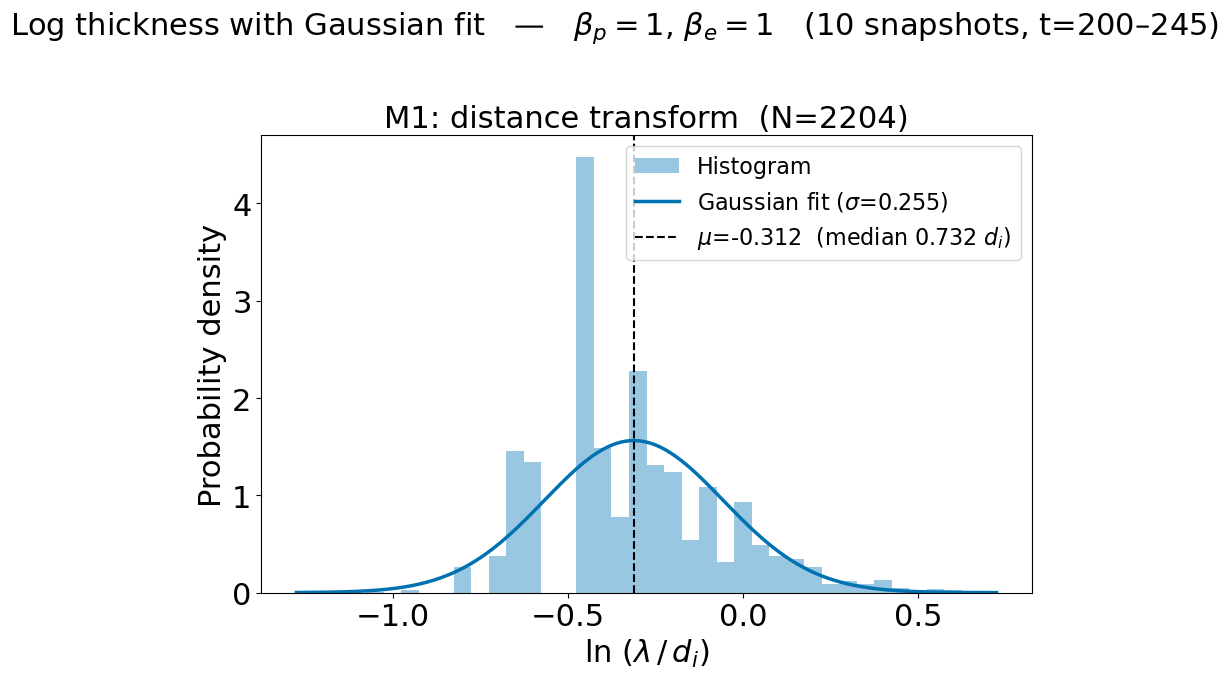

In [3]:
# =====================================================================
#  Current-sheet thickness (M1 only), plotted in LOG SPACE with a Gaussian fit
# ---------------------------------------------------------------------
#  M1 = the largest circle that fits inside the sheet, i.e. 2 x the maximum of
#  the distance transform. That is the whole measurement -- no centreline, no
#  profile fitting.
#
#  WHY LOG SPACE. A log-normal distribution becomes an ordinary Gaussian once
#  you take logs, so fitting a Gaussian to ln(thickness) gives exactly the same
#  answer as fitting a log-normal to the thickness:
#        sigma  = std( ln x )            (the log-normal shape parameter)
#        median = exp( mean( ln x ) )    (the log-normal 'scale')
#  Nothing new numerically -- but in log space the fit is a SYMMETRIC bell, so
#  skewness, fat tails and second populations are visible. Under a log-normal
#  curve drawn on a skewed linear histogram they are not.
#
#  The fit is maximum-likelihood on the raw values, so it does NOT depend on the
#  binning: the histogram is only for looking at.
#
#  Must already exist in your session:
#    iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets
# =====================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.stats import norm, skew, kurtosis
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({
    'font.size': 22,
    'axes.titlesize': 22,
    'axes.labelsize': 22,
    'xtick.labelsize': 22,
    'ytick.labelsize': 22,
    'legend.fontsize': 22,
    'figure.titlesize': 22,
})

# -----------------------------
# USER SETTINGS
# -----------------------------
BETA      = 1                              # beta_p = 1  (beta_e = 1 fixed)
TIMES     = list(range(200, 250, 5))       # 200, 205, ..., 245  -> 10 snapshots pooled
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)

cache_dir = str(CACHE / "filtered_cache_Jz")
out_fig   = str(RESULTS / f"thickness_log_gaussian_beta{BETA}.png")
out_npz   = str(RESULTS / f"pooled_thickness_m1_beta{BETA}.npz")

PX_PER_DI    = 16.0
CONNECTIVITY = 2                           # 8-connectivity
NBINS        = 40
COLOUR       = "#0072B2"
N_WORKERS    = min(len(TIMES), os.cpu_count() or 1)
THREADS_PER_WORKER = 1
dx = dy      = 0.0625

FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

os.makedirs(cache_dir, exist_ok=True)


def _init_worker(n_threads):
    if threadpool_limits is not None:
        threadpool_limits(limits=n_threads)


# -----------------------------
# One snapshot -> (time, M1 thicknesses in d_i)
# -----------------------------
def extract(time):
    n_iter, Xi = FILTER_PARAMS[BETA]
    base_path = f"{base_root}/beta_p_{BETA}/beta_e_1/"
    with h5py.File(base_path + f"Bx_{sim_tag}_t{time}.h5", "r") as fBx, \
         h5py.File(base_path + f"By_{sim_tag}_t{time}.h5", "r") as fBy, \
         h5py.File(base_path + f"Bz_{sim_tag}_t{time}.h5", "r") as fBz:
        data_Bx, data_By, data_Bz = fBx["DS1"][:].T, fBy["DS1"][:].T, fBz["DS1"][:].T

    cache_file = f"{cache_dir}/filtered_beta_{BETA}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        data_Bx_f, data_By_f, data_Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f)

    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    cleaned_mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)

    labeled = measure.label(cleaned_mask, connectivity=CONNECTIVITY)

    # M1: for each sheet, 2 x the largest distance-to-edge = the inscribed circle
    thickness = []
    for k in range(1, int(labeled.max()) + 1):
        edt = ndi.distance_transform_edt(labeled == k)
        thickness.append(2.0 * float(edt.max()))

    m1 = np.array(thickness, float)
    return time, m1[m1 > 0] / PX_PER_DI


# -----------------------------
if __name__ == "__main__":
    # ---- extract all snapshots in parallel ----
    results = []
    if N_WORKERS == 1:
        for t in TIMES:
            try:
                r = extract(t); results.append(r)
                print(f"t={t}: {r[1].size} sheets", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)
    else:
        ctx = mp.get_context("fork")
        if threadpool_limits is None:
            print("note: threadpoolctl not found -> workers may oversubscribe threads.",
                  flush=True)
        print(f"Extracting {len(TIMES)} snapshots across {N_WORKERS} workers ...", flush=True)
        with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                                 initializer=_init_worker,
                                 initargs=(THREADS_PER_WORKER,)) as ex:
            futs = {ex.submit(extract, t): t for t in TIMES}
            for fut in as_completed(futs):
                t = futs[fut]
                try:
                    r = fut.result(); results.append(r)
                    print(f"t={t}: {r[1].size} sheets", flush=True)
                except FileNotFoundError:
                    print(f"t={t}: missing file, skipped", flush=True)

    if not results:
        raise SystemExit("No snapshots extracted (check paths / TIMES).")
    results.sort(key=lambda r: r[0])
    times_done = [r[0] for r in results]

    # ---- pool every sheet from every snapshot ----
    thickness = np.concatenate([r[1] for r in results])
    thickness = thickness[np.isfinite(thickness) & (thickness > 0)]
    print(f"\npooled {thickness.size} sheets from {len(times_done)} snapshots")

    # ---- fit a Gaussian to ln(thickness) ----
    # This is maximum likelihood, and for a Gaussian that is just the mean and
    # standard deviation of the logs. Closed form: nothing to converge, and it
    # never sees the histogram, so the fit is independent of NBINS.
    log_thickness = np.log(thickness)
    mu, sigma = norm.fit(log_thickness)

    median = float(np.exp(mu))          # exp(mean of logs) = the log-normal median
    g1 = float(skew(log_thickness))     # 0 if the logs are truly Gaussian
    g2 = float(kurtosis(log_thickness))  # 0 (excess) if truly Gaussian

    # ---- the plot ----
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.hist(log_thickness, bins=NBINS, density=True, alpha=0.4, color=COLOUR,
            label="Histogram")
    grid = np.linspace(log_thickness.min(), log_thickness.max(), 400)
    ax.plot(grid, norm.pdf(grid, mu, sigma), color=COLOUR, lw=2.5,
            label=rf"Gaussian fit ($\sigma$={sigma:.3f})")
    ax.axvline(mu, color="k", ls="--", lw=1.5,
               label=rf"$\mu$={mu:.3f}  (median {median:.3f} $d_i$)")
    ax.set_xlabel(r"$\ln\,(\lambda\,/\,d_i)$")
    ax.set_ylabel("Probability density")
    ax.set_title(f"M1: distance transform  (N={thickness.size})")
    ax.legend(fontsize=16)

    fig.suptitle(rf"Log thickness with Gaussian fit   —   $\beta_p = {BETA}$, "
                 rf"$\beta_e = 1$   ({len(times_done)} snapshots, "
                 rf"t={times_done[0]}–{times_done[-1]})", y=0.99)
    fig.tight_layout()
    fig.savefig(out_fig, dpi=300, bbox_inches="tight")
    print(f"saved {out_fig}")

    # ---- save + summary ----
    np.savez_compressed(out_npz, times=np.array(times_done), thickness_di=thickness)
    print(f"saved {out_npz}")

    print(f"\n--- Gaussian fit to ln(thickness), N = {thickness.size} ---")
    print(f"  mu     = {mu:.4f}      -> median = exp(mu) = {median:.4f} d_i")
    print(f"  sigma  = {sigma:.4f}   (the log-normal shape parameter)")
    print(f"  SE(mu) = {sigma/np.sqrt(thickness.size):.5f}, "
          f"SE(sigma) = {sigma/np.sqrt(2*thickness.size):.5f}")
    print(f"\n  empirical median = {np.median(thickness):.4f} d_i "
          f"(fitted/empirical = {median/np.median(thickness):.3f}; 1.000 if log-normal)")
    print(f"  skew(ln x)            = {g1:+.3f}   (0 if Gaussian)")
    print(f"  excess kurtosis(ln x) = {g2:+.3f}   (0 if Gaussian)")
    print("\n  Judge by the SIZE of skew and kurtosis, not by a p-value: p-values")
    print("  shrink as N grows, so with thousands of sheets they measure N as much")
    print("  as they measure any real departure.")

Extracting 10 snapshots across 10 workers ...
t=245: 197 sheets
t=230: 212 sheets
t=225: 215 sheets
t=210: 235 sheets
t=235: 206 sheets
t=240: 214 sheets
t=220: 208 sheets
t=205: 242 sheets
t=215: 231 sheets
t=200: 244 sheets

pooled 2204 sheets from 10 snapshots
saved thickness_log_gaussian_m2_beta1.png
saved pooled_thickness_m2_beta1.npz

--- Gaussian fit to ln(thickness), N = 2204 ---
  mu     = -0.3337      -> median = exp(mu) = 0.7163 d_i
  sigma  = 0.5431   (the log-normal shape parameter)
  SE(mu) = 0.01157, SE(sigma) = 0.00818

  empirical median = 0.6250 d_i (fitted/empirical = 1.146; 1.000 if log-normal)
  skew(ln x)            = +1.601   (0 if Gaussian)
  excess kurtosis(ln x) = +3.259   (0 if Gaussian)

  Judge by the SIZE of skew and kurtosis, not by a p-value: p-values
  shrink as N grows, so with thousands of sheets they measure N as much
  as they measure any real departure.


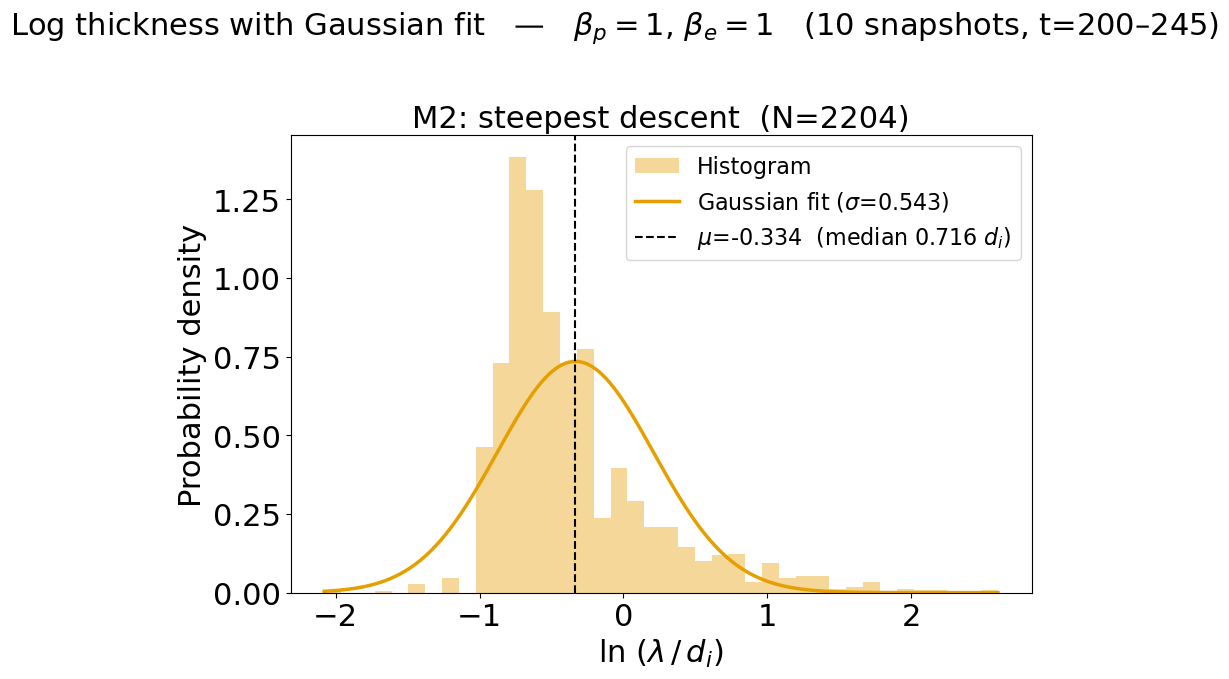

In [4]:
# =====================================================================
#  Current-sheet thickness (M2 only), plotted in LOG SPACE with a Gaussian fit
# ---------------------------------------------------------------------
#  M2 = "walk downhill". Start at the BRIGHTEST pixel in the sheet, work out
#  which way the (smoothed) current falls off fastest, and walk that way in a
#  straight line until you step outside the sheet. Do the same in the opposite
#  direction. The two distances added together are the thickness.
#
#  How that differs from M1, which is worth keeping in mind:
#    * M1 finds the widest point ANYWHERE in the sheet; M2 measures across one
#      specific point, the current peak.
#    * M2 is a straight chord, so if the descent direction is not exactly
#      perpendicular to the sheet the chord is longer than the true width.
#    * M2 depends on SMOOTH_SIGMA, because the direction comes from the
#      smoothed field. M1 has no such knob.
#
#  WHY LOG SPACE. A log-normal distribution becomes an ordinary Gaussian once
#  you take logs, so fitting a Gaussian to ln(thickness) gives exactly the same
#  answer as fitting a log-normal to the thickness:
#        sigma  = std( ln x )            (the log-normal shape parameter)
#        median = exp( mean( ln x ) )    (the log-normal 'scale')
#  Nothing new numerically -- but in log space the fit is a SYMMETRIC bell, so
#  skewness, fat tails and second populations are visible. Under a log-normal
#  curve drawn on a skewed linear histogram they are not.
#
#  The fit is maximum-likelihood on the raw values, so it does NOT depend on the
#  binning: the histogram is only for looking at.
#
#  Must already exist in your session:
#    iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets
# =====================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy.ndimage import gaussian_filter
from scipy.stats import norm, skew, kurtosis
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({
    'font.size': 22,
    'axes.titlesize': 22,
    'axes.labelsize': 22,
    'xtick.labelsize': 22,
    'ytick.labelsize': 22,
    'legend.fontsize': 22,
    'figure.titlesize': 22,
})

# -----------------------------
# USER SETTINGS
# -----------------------------
BETA      = 1                              # beta_p = 1  (beta_e = 1 fixed)
TIMES     = list(range(200, 250, 5))       # 200, 205, ..., 245  -> 10 snapshots pooled
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)

cache_dir = str(CACHE / "filtered_cache_Jz")
out_fig   = str(RESULTS / f"thickness_log_gaussian_m2_beta{BETA}.png")
out_npz   = str(RESULTS / f"pooled_thickness_m2_beta{BETA}.npz")

PX_PER_DI    = 16.0
CONNECTIVITY = 2                           # 8-connectivity
NBINS        = 40
COLOUR       = "#E69F00"      # M2 orange, matching the method colours
SMOOTH_SIGMA = 3              # smoothing used ONLY to pick the walk direction
N_WORKERS    = min(len(TIMES), os.cpu_count() or 1)
THREADS_PER_WORKER = 1
dx = dy      = 0.0625

FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

os.makedirs(cache_dir, exist_ok=True)


def _init_worker(n_threads):
    if threadpool_limits is not None:
        threadpool_limits(limits=n_threads)


def walk_to_edge(mask, x0, y0, dx_, dy_, step=1, max_steps=1000):
    """Walk in a straight line from (x0, y0) along (dx_, dy_) until the next
    step would land outside the sheet, and return how far we got."""
    nx, ny = mask.shape
    xf, yf, s = float(x0), float(y0), 0
    while s < max_steps:
        xn, yn = xf + dx_ * step, yf + dy_ * step
        xi, yi = int(round(xn)), int(round(yn))
        if xi < 0 or yi < 0 or xi >= nx or yi >= ny:
            break
        if not mask[xi, yi]:
            break
        xf, yf, s = xn, yn, s + 1
    return np.hypot(xf - x0, yf - y0)


# -----------------------------
# One snapshot -> (time, M1 thicknesses in d_i)
# -----------------------------
def extract(time):
    n_iter, Xi = FILTER_PARAMS[BETA]
    base_path = f"{base_root}/beta_p_{BETA}/beta_e_1/"
    with h5py.File(base_path + f"Bx_{sim_tag}_t{time}.h5", "r") as fBx, \
         h5py.File(base_path + f"By_{sim_tag}_t{time}.h5", "r") as fBy, \
         h5py.File(base_path + f"Bz_{sim_tag}_t{time}.h5", "r") as fBz:
        data_Bx, data_By, data_Bz = fBx["DS1"][:].T, fBy["DS1"][:].T, fBz["DS1"][:].T

    cache_file = f"{cache_dir}/filtered_beta_{BETA}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        data_Bx_f, data_By_f, data_Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f)

    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    cleaned_mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)

    labeled = measure.label(cleaned_mask, connectivity=CONNECTIVITY)

    # the walk direction comes from the SMOOTHED current, so it is not thrown off
    # by pixel-to-pixel noise; the walk itself uses the unsmoothed sheet mask
    J2_smooth = gaussian_filter(J2, sigma=SMOOTH_SIGMA)
    gx, gy = np.gradient(J2_smooth)

    # M2: from the brightest pixel of each sheet, walk downhill to both edges
    thickness = []
    for k in range(1, int(labeled.max()) + 1):
        region = (labeled == k)
        xs_r, ys_r = np.where(region)
        peak = int(np.argmax(J2[region]))
        xm, ym = int(xs_r[peak]), int(ys_r[peak])      # brightest pixel in this sheet

        gvec = np.array([gx[xm, ym], gy[xm, ym]])
        if np.allclose(gvec, 0):
            continue                                   # flat here: no direction to walk
        v = -gvec / np.linalg.norm(gvec)               # unit vector, pointing downhill
        dx_, dy_ = float(v[0]), float(v[1])

        thickness.append(walk_to_edge(cleaned_mask, xm, ym,  dx_,  dy_)
                         + walk_to_edge(cleaned_mask, xm, ym, -dx_, -dy_))

    m2 = np.array(thickness, float)
    return time, m2[m2 > 0] / PX_PER_DI


# -----------------------------
if __name__ == "__main__":
    # ---- extract all snapshots in parallel ----
    results = []
    if N_WORKERS == 1:
        for t in TIMES:
            try:
                r = extract(t); results.append(r)
                print(f"t={t}: {r[1].size} sheets", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)
    else:
        ctx = mp.get_context("fork")
        if threadpool_limits is None:
            print("note: threadpoolctl not found -> workers may oversubscribe threads.",
                  flush=True)
        print(f"Extracting {len(TIMES)} snapshots across {N_WORKERS} workers ...", flush=True)
        with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                                 initializer=_init_worker,
                                 initargs=(THREADS_PER_WORKER,)) as ex:
            futs = {ex.submit(extract, t): t for t in TIMES}
            for fut in as_completed(futs):
                t = futs[fut]
                try:
                    r = fut.result(); results.append(r)
                    print(f"t={t}: {r[1].size} sheets", flush=True)
                except FileNotFoundError:
                    print(f"t={t}: missing file, skipped", flush=True)

    if not results:
        raise SystemExit("No snapshots extracted (check paths / TIMES).")
    results.sort(key=lambda r: r[0])
    times_done = [r[0] for r in results]

    # ---- pool every sheet from every snapshot ----
    thickness = np.concatenate([r[1] for r in results])
    thickness = thickness[np.isfinite(thickness) & (thickness > 0)]
    print(f"\npooled {thickness.size} sheets from {len(times_done)} snapshots")

    # ---- fit a Gaussian to ln(thickness) ----
    # This is maximum likelihood, and for a Gaussian that is just the mean and
    # standard deviation of the logs. Closed form: nothing to converge, and it
    # never sees the histogram, so the fit is independent of NBINS.
    log_thickness = np.log(thickness)
    mu, sigma = norm.fit(log_thickness)

    median = float(np.exp(mu))          # exp(mean of logs) = the log-normal median
    g1 = float(skew(log_thickness))     # 0 if the logs are truly Gaussian
    g2 = float(kurtosis(log_thickness))  # 0 (excess) if truly Gaussian

    # ---- the plot ----
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.hist(log_thickness, bins=NBINS, density=True, alpha=0.4, color=COLOUR,
            label="Histogram")
    grid = np.linspace(log_thickness.min(), log_thickness.max(), 400)
    ax.plot(grid, norm.pdf(grid, mu, sigma), color=COLOUR, lw=2.5,
            label=rf"Gaussian fit ($\sigma$={sigma:.3f})")
    ax.axvline(mu, color="k", ls="--", lw=1.5,
               label=rf"$\mu$={mu:.3f}  (median {median:.3f} $d_i$)")
    ax.set_xlabel(r"$\ln\,(\lambda\,/\,d_i)$")
    ax.set_ylabel("Probability density")
    ax.set_title(f"M2: steepest descent  (N={thickness.size})")
    ax.legend(fontsize=16)

    fig.suptitle(rf"Log thickness with Gaussian fit   —   $\beta_p = {BETA}$, "
                 rf"$\beta_e = 1$   ({len(times_done)} snapshots, "
                 rf"t={times_done[0]}–{times_done[-1]})", y=0.99)
    fig.tight_layout()
    fig.savefig(out_fig, dpi=300, bbox_inches="tight")
    print(f"saved {out_fig}")

    # ---- save + summary ----
    np.savez_compressed(out_npz, times=np.array(times_done), thickness_di=thickness)
    print(f"saved {out_npz}")

    print(f"\n--- Gaussian fit to ln(thickness), N = {thickness.size} ---")
    print(f"  mu     = {mu:.4f}      -> median = exp(mu) = {median:.4f} d_i")
    print(f"  sigma  = {sigma:.4f}   (the log-normal shape parameter)")
    print(f"  SE(mu) = {sigma/np.sqrt(thickness.size):.5f}, "
          f"SE(sigma) = {sigma/np.sqrt(2*thickness.size):.5f}")
    print(f"\n  empirical median = {np.median(thickness):.4f} d_i "
          f"(fitted/empirical = {median/np.median(thickness):.3f}; 1.000 if log-normal)")
    print(f"  skew(ln x)            = {g1:+.3f}   (0 if Gaussian)")
    print(f"  excess kurtosis(ln x) = {g2:+.3f}   (0 if Gaussian)")
    print("\n  Judge by the SIZE of skew and kurtosis, not by a p-value: p-values")
    print("  shrink as N grows, so with thousands of sheets they measure N as much")
    print("  as they measure any real departure.")

Extracting 10 snapshots across 10 workers ...
t=245: 196 of 197 sheets fitted
t=210: 230 of 235 sheets fitted
t=230: 210 of 212 sheets fitted
t=225: 211 of 215 sheets fitted
t=240: 213 of 214 sheets fitted
t=235: 204 of 206 sheets fitted
t=220: 206 of 208 sheets fitted
t=215: 228 of 231 sheets fitted
t=200: 240 of 244 sheets fitted
t=205: 236 of 242 sheets fitted

pooled 2174 sheets from 10 snapshots
  30 of 2204 sheets (1.4%) had no usable bell-curve fit and are NOT in the sample
saved thickness_log_gaussian_m3_beta1.png
saved pooled_thickness_m3_beta1.npz

--- Gaussian fit to ln(thickness), N = 2174 ---
  mu     = -0.1474      -> median = exp(mu) = 0.8629 d_i
  sigma  = 0.4268   (the log-normal shape parameter)
  SE(mu) = 0.00915, SE(sigma) = 0.00647

  empirical median = 0.7904 d_i (fitted/empirical = 1.092; 1.000 if log-normal)
  skew(ln x)            = +1.440   (0 if Gaussian)
  excess kurtosis(ln x) = +3.172   (0 if Gaussian)

  Judge by the SIZE of skew and kurtosis, not by a p-

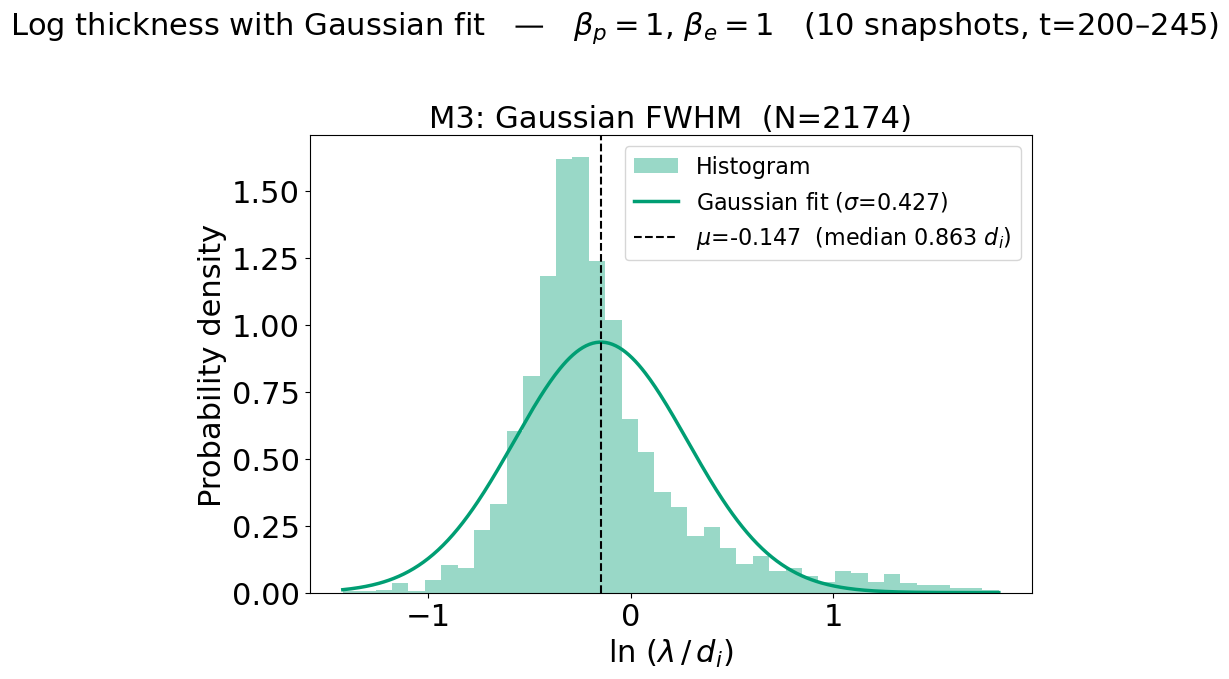

In [6]:
# =====================================================================
#  Current-sheet thickness (M3 only), plotted in LOG SPACE with a Gaussian fit
# ---------------------------------------------------------------------
#  M3 = "fit the bump". Find the direction the (smoothed) current falls off
#  fastest at the sheet's brightest pixel -- same direction M2 uses -- then read
#  the current along that line and fit a bell curve to it. The thickness is the
#  full width at half maximum of that bell:
#        FWHM = 2 sqrt(2 ln 2) * sigma  ~=  2.3548 * sigma
#
#  CAREFUL, TWO DIFFERENT GAUSSIAN FITS LIVE IN THIS FILE:
#    1. per sheet, a Gaussian CURVE is fitted to the |J| profile -- nonlinear
#       least squares (curve_fit), needs starting guesses, and CAN FAIL.
#    2. at the end, a Gaussian DISTRIBUTION is fitted to ln(thickness) --
#       closed-form maximum likelihood, cannot fail.
#
#  How M3 differs from M1 and M2:
#    * it uses the current PROFILE, not the sheet mask, so the answer does not
#      depend on where the detection threshold put the edge.
#    * it fits a pedestal B, so a sheet sitting on a background of |J| is not
#      artificially widened.
#    * unlike M1 and M2 it can RETURN NOTHING: a flat, double-peaked or
#      truncated profile makes the fit fail. Those sheets drop out of the
#      sample, so M3's N is smaller -- the script reports how many.
#
#  WHY LOG SPACE. A log-normal distribution becomes an ordinary Gaussian once
#  you take logs, so fitting a Gaussian to ln(thickness) gives exactly the same
#  answer as fitting a log-normal to the thickness:
#        sigma  = std( ln x )            (the log-normal shape parameter)
#        median = exp( mean( ln x ) )    (the log-normal 'scale')
#  Nothing new numerically -- but in log space the fit is a SYMMETRIC bell, so
#  skewness, fat tails and second populations are visible. Under a log-normal
#  curve drawn on a skewed linear histogram they are not.
#
#  The fit is maximum-likelihood on the raw values, so it does NOT depend on the
#  binning: the histogram is only for looking at.
#
#  Must already exist in your session:
#    iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets
# =====================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
from scipy.stats import norm, skew, kurtosis
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({
    'font.size': 22,
    'axes.titlesize': 22,
    'axes.labelsize': 22,
    'xtick.labelsize': 22,
    'ytick.labelsize': 22,
    'legend.fontsize': 22,
    'figure.titlesize': 22,
})

# -----------------------------
# USER SETTINGS
# -----------------------------
BETA      = 1                              # beta_p = 1  (beta_e = 1 fixed)
TIMES     = list(range(200, 250, 5))       # 200, 205, ..., 245  -> 10 snapshots pooled
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)

cache_dir = str(CACHE / "filtered_cache_Jz")
out_fig   = str(RESULTS / f"thickness_log_gaussian_m3_beta{BETA}.png")
out_npz   = str(RESULTS / f"pooled_thickness_m3_beta{BETA}.npz")

PX_PER_DI    = 16.0
CONNECTIVITY = 2                           # 8-connectivity
NBINS        = 40
COLOUR       = "#009E73"      # M3 green, matching the method colours
SMOOTH_SIGMA = 3              # smoothing used ONLY to pick the profile direction

# how far along the line to sample the profile, and how finely
MAX_LEN      = 60             # never sample further than this from the peak (px)
SUBPIX_STEP  = 0.5            # sampling step along the line (px)
MARGIN_FRAC  = 0.5            # sample this much PAST the mask edge, so the fit sees
                              # the shoulders of the bump and can find the pedestal
MIN_HALF     = 6.0            # always sample at least this far each way (px)
MAX_FWHM_PX  = 100            # reject absurd fits (px); see the direction caveat below
N_WORKERS    = min(len(TIMES), os.cpu_count() or 1)
THREADS_PER_WORKER = 1
dx = dy      = 0.0625

FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

os.makedirs(cache_dir, exist_ok=True)


def _init_worker(n_threads):
    if threadpool_limits is not None:
        threadpool_limits(limits=n_threads)


def bell(t, A, mu, sigma, B):
    """A bump of height A at position mu and width sigma, sitting on a floor B."""
    return A * np.exp(-(t - mu) ** 2 / (2 * sigma ** 2)) + B


def fwhm_along(J2, mask, xm, ym, dx_, dy_):
    """Sample |J| along the line through (xm, ym) in direction (dx_, dy_), fit a
    bell curve to it, and return the full width at half maximum in pixels.
    Returns NaN if there is nothing sensible to fit."""
    if dx_ == 0 and dy_ == 0:
        return np.nan
    nx, ny = mask.shape

    # how far the sheet extends each way, so we know how much line to sample
    def distance_to_edge(sx, sy):
        d = 0.0
        while d < MAX_LEN:
            dn = d + SUBPIX_STEP
            xi, yi = int(round(xm + sx * dn)) % nx, int(round(ym + sy * dn)) % ny
            if not mask[xi, yi]:
                break
            d = dn
        return d

    half_f = min(MAX_LEN, max(MIN_HALF, distance_to_edge(dx_, dy_) * (1 + MARGIN_FRAC)))
    half_b = min(MAX_LEN, max(MIN_HALF, distance_to_edge(-dx_, -dy_) * (1 + MARGIN_FRAC)))

    # read the current along the line (sub-pixel, wrapping at the box edges)
    t = np.arange(-half_b, half_f + SUBPIX_STEP, SUBPIX_STEP)
    profile = ndi.map_coordinates(J2, np.vstack([xm + t * dx_, ym + t * dy_]),
                                  order=1, mode="grid-wrap")
    if len(profile) < 4:
        return np.nan

    # starting guesses: floor, height, peak position, and width from the half-max points
    B0 = float(profile.min())
    A0 = float(profile.max() - profile.min())
    if A0 <= 0:
        return np.nan
    mu0 = float(t[np.argmax(profile)])
    above = np.where(profile >= B0 + 0.5 * A0)[0]
    sigma0 = (max(1.0, (t[above[-1]] - t[above[0]]) / 2.3548)
              if above.size >= 2 else max(2.0, (half_f + half_b) / 6.0))
    span = float(t.max() - t.min())
    sigma0 = min(sigma0, 0.99 * span)

    bounds = ([0.0, t.min() - 1, 1e-3, -np.inf], [np.inf, t.max() + 1, span, np.inf])
    try:
        popt, _ = curve_fit(bell, t, profile, p0=[A0, mu0, sigma0, B0],
                            bounds=bounds, maxfev=10000)
    except (RuntimeError, ValueError):
        return np.nan                     # profile too flat / odd for a bell curve
    return 2 * np.sqrt(2 * np.log(2)) * abs(popt[2])


# -----------------------------
# One snapshot -> (time, M1 thicknesses in d_i)
# -----------------------------
def extract(time):
    n_iter, Xi = FILTER_PARAMS[BETA]
    base_path = f"{base_root}/beta_p_{BETA}/beta_e_1/"
    with h5py.File(base_path + f"Bx_{sim_tag}_t{time}.h5", "r") as fBx, \
         h5py.File(base_path + f"By_{sim_tag}_t{time}.h5", "r") as fBy, \
         h5py.File(base_path + f"Bz_{sim_tag}_t{time}.h5", "r") as fBz:
        data_Bx, data_By, data_Bz = fBx["DS1"][:].T, fBy["DS1"][:].T, fBz["DS1"][:].T

    cache_file = f"{cache_dir}/filtered_beta_{BETA}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cache_file):
        d = np.load(cache_file)
        data_Bx_f, data_By_f, data_Bz_f = d["Bx"], d["By"], d["Bz"]
    else:
        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi)
        np.savez_compressed(cache_file, Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f)

    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    J2 = np.abs(Jz)

    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    cleaned_mask = morphology.remove_small_objects(mask.astype(bool), min_size=500)

    labeled = measure.label(cleaned_mask, connectivity=CONNECTIVITY)

    # the walk direction comes from the SMOOTHED current, so it is not thrown off
    # by pixel-to-pixel noise; the walk itself uses the unsmoothed sheet mask
    J2_smooth = gaussian_filter(J2, sigma=SMOOTH_SIGMA)
    gx, gy = np.gradient(J2_smooth)

    # M3: at each sheet's brightest pixel, fit a bell curve across the sheet
    thickness = []
    n_sheets = int(labeled.max())
    for k in range(1, n_sheets + 1):
        region = (labeled == k)
        xs_r, ys_r = np.where(region)
        peak = int(np.argmax(J2[region]))
        xm, ym = int(xs_r[peak]), int(ys_r[peak])      # brightest pixel in this sheet

        gvec = np.array([gx[xm, ym], gy[xm, ym]])
        if np.allclose(gvec, 0):
            continue                                   # flat here: no direction to take
        v = -gvec / np.linalg.norm(gvec)               # unit vector, pointing downhill
        thickness.append(fwhm_along(J2, cleaned_mask, xm, ym, float(v[0]), float(v[1])))

    m3 = np.array(thickness, float)
    keep = np.isfinite(m3) & (m3 > 0) & (m3 <= MAX_FWHM_PX)
    # n_sheets is reported so the fit-failure rate is visible: unlike M1 and M2,
    # M3 loses sheets whose profile could not be fitted
    return time, m3[keep] / PX_PER_DI, n_sheets


# -----------------------------
if __name__ == "__main__":
    # ---- extract all snapshots in parallel ----
    results = []
    if N_WORKERS == 1:
        for t in TIMES:
            try:
                r = extract(t); results.append(r)
                print(f"t={t}: {r[1].size} of {r[2]} sheets fitted", flush=True)
            except FileNotFoundError:
                print(f"t={t}: missing file, skipped", flush=True)
    else:
        ctx = mp.get_context("fork")
        if threadpool_limits is None:
            print("note: threadpoolctl not found -> workers may oversubscribe threads.",
                  flush=True)
        print(f"Extracting {len(TIMES)} snapshots across {N_WORKERS} workers ...", flush=True)
        with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=ctx,
                                 initializer=_init_worker,
                                 initargs=(THREADS_PER_WORKER,)) as ex:
            futs = {ex.submit(extract, t): t for t in TIMES}
            for fut in as_completed(futs):
                t = futs[fut]
                try:
                    r = fut.result(); results.append(r)
                    print(f"t={t}: {r[1].size} of {r[2]} sheets fitted", flush=True)
                except FileNotFoundError:
                    print(f"t={t}: missing file, skipped", flush=True)

    if not results:
        raise SystemExit("No snapshots extracted (check paths / TIMES).")
    results.sort(key=lambda r: r[0])
    times_done = [r[0] for r in results]

    # ---- pool every sheet from every snapshot ----
    thickness = np.concatenate([r[1] for r in results])
    thickness = thickness[np.isfinite(thickness) & (thickness > 0)]
    n_attempted = sum(r[2] for r in results)
    print(f"\npooled {thickness.size} sheets from {len(times_done)} snapshots")
    print(f"  {n_attempted - thickness.size} of {n_attempted} sheets "
          f"({100*(n_attempted - thickness.size)/max(n_attempted,1):.1f}%) had no usable "
          f"bell-curve fit and are NOT in the sample")

    # ---- fit a Gaussian to ln(thickness) ----
    # This is maximum likelihood, and for a Gaussian that is just the mean and
    # standard deviation of the logs. Closed form: nothing to converge, and it
    # never sees the histogram, so the fit is independent of NBINS.
    log_thickness = np.log(thickness)
    mu, sigma = norm.fit(log_thickness)

    median = float(np.exp(mu))          # exp(mean of logs) = the log-normal median
    g1 = float(skew(log_thickness))     # 0 if the logs are truly Gaussian
    g2 = float(kurtosis(log_thickness))  # 0 (excess) if truly Gaussian

    # ---- the plot ----
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.hist(log_thickness, bins=NBINS, density=True, alpha=0.4, color=COLOUR,
            label="Histogram")
    grid = np.linspace(log_thickness.min(), log_thickness.max(), 400)
    ax.plot(grid, norm.pdf(grid, mu, sigma), color=COLOUR, lw=2.5,
            label=rf"Gaussian fit ($\sigma$={sigma:.3f})")
    ax.axvline(mu, color="k", ls="--", lw=1.5,
               label=rf"$\mu$={mu:.3f}  (median {median:.3f} $d_i$)")
    ax.set_xlabel(r"$\ln\,(\lambda\,/\,d_i)$")
    ax.set_ylabel("Probability density")
    ax.set_title(f"M3: Gaussian FWHM  (N={thickness.size})")
    ax.legend(fontsize=16)

    fig.suptitle(rf"Log thickness with Gaussian fit   —   $\beta_p = {BETA}$, "
                 rf"$\beta_e = 1$   ({len(times_done)} snapshots, "
                 rf"t={times_done[0]}–{times_done[-1]})", y=0.99)
    fig.tight_layout()
    fig.savefig(out_fig, dpi=300, bbox_inches="tight")
    print(f"saved {out_fig}")

    # ---- save + summary ----
    np.savez_compressed(out_npz, times=np.array(times_done), thickness_di=thickness)
    print(f"saved {out_npz}")

    print(f"\n--- Gaussian fit to ln(thickness), N = {thickness.size} ---")
    print(f"  mu     = {mu:.4f}      -> median = exp(mu) = {median:.4f} d_i")
    print(f"  sigma  = {sigma:.4f}   (the log-normal shape parameter)")
    print(f"  SE(mu) = {sigma/np.sqrt(thickness.size):.5f}, "
          f"SE(sigma) = {sigma/np.sqrt(2*thickness.size):.5f}")
    print(f"\n  empirical median = {np.median(thickness):.4f} d_i "
          f"(fitted/empirical = {median/np.median(thickness):.3f}; 1.000 if log-normal)")
    print(f"  skew(ln x)            = {g1:+.3f}   (0 if Gaussian)")
    print(f"  excess kurtosis(ln x) = {g2:+.3f}   (0 if Gaussian)")
    print("\n  Judge by the SIZE of skew and kurtosis, not by a p-value: p-values")
    print("  shrink as N grows, so with thousands of sheets they measure N as much")
    print("  as they measure any real departure.")

measuring 10 snapshots on 10 workers ...
  t=245: 197 sheets
  t=230: 212 sheets
  t=220: 208 sheets
  t=210: 235 sheets
  t=225: 215 sheets
  t=240: 214 sheets
  t=235: 206 sheets
  t=215: 231 sheets
  t=205: 242 sheets
  t=200: 244 sheets

saved paired_thickness_beta1.csv  (2204 sheets)
  M1:  2204 of 2204 sheets measured (0.0% missing), median 0.663 d_i
  M2:  2204 of 2204 sheets measured (0.0% missing), median 0.625 d_i
  M3:  2174 of 2204 sheets measured (1.4% missing), median 0.790 d_i


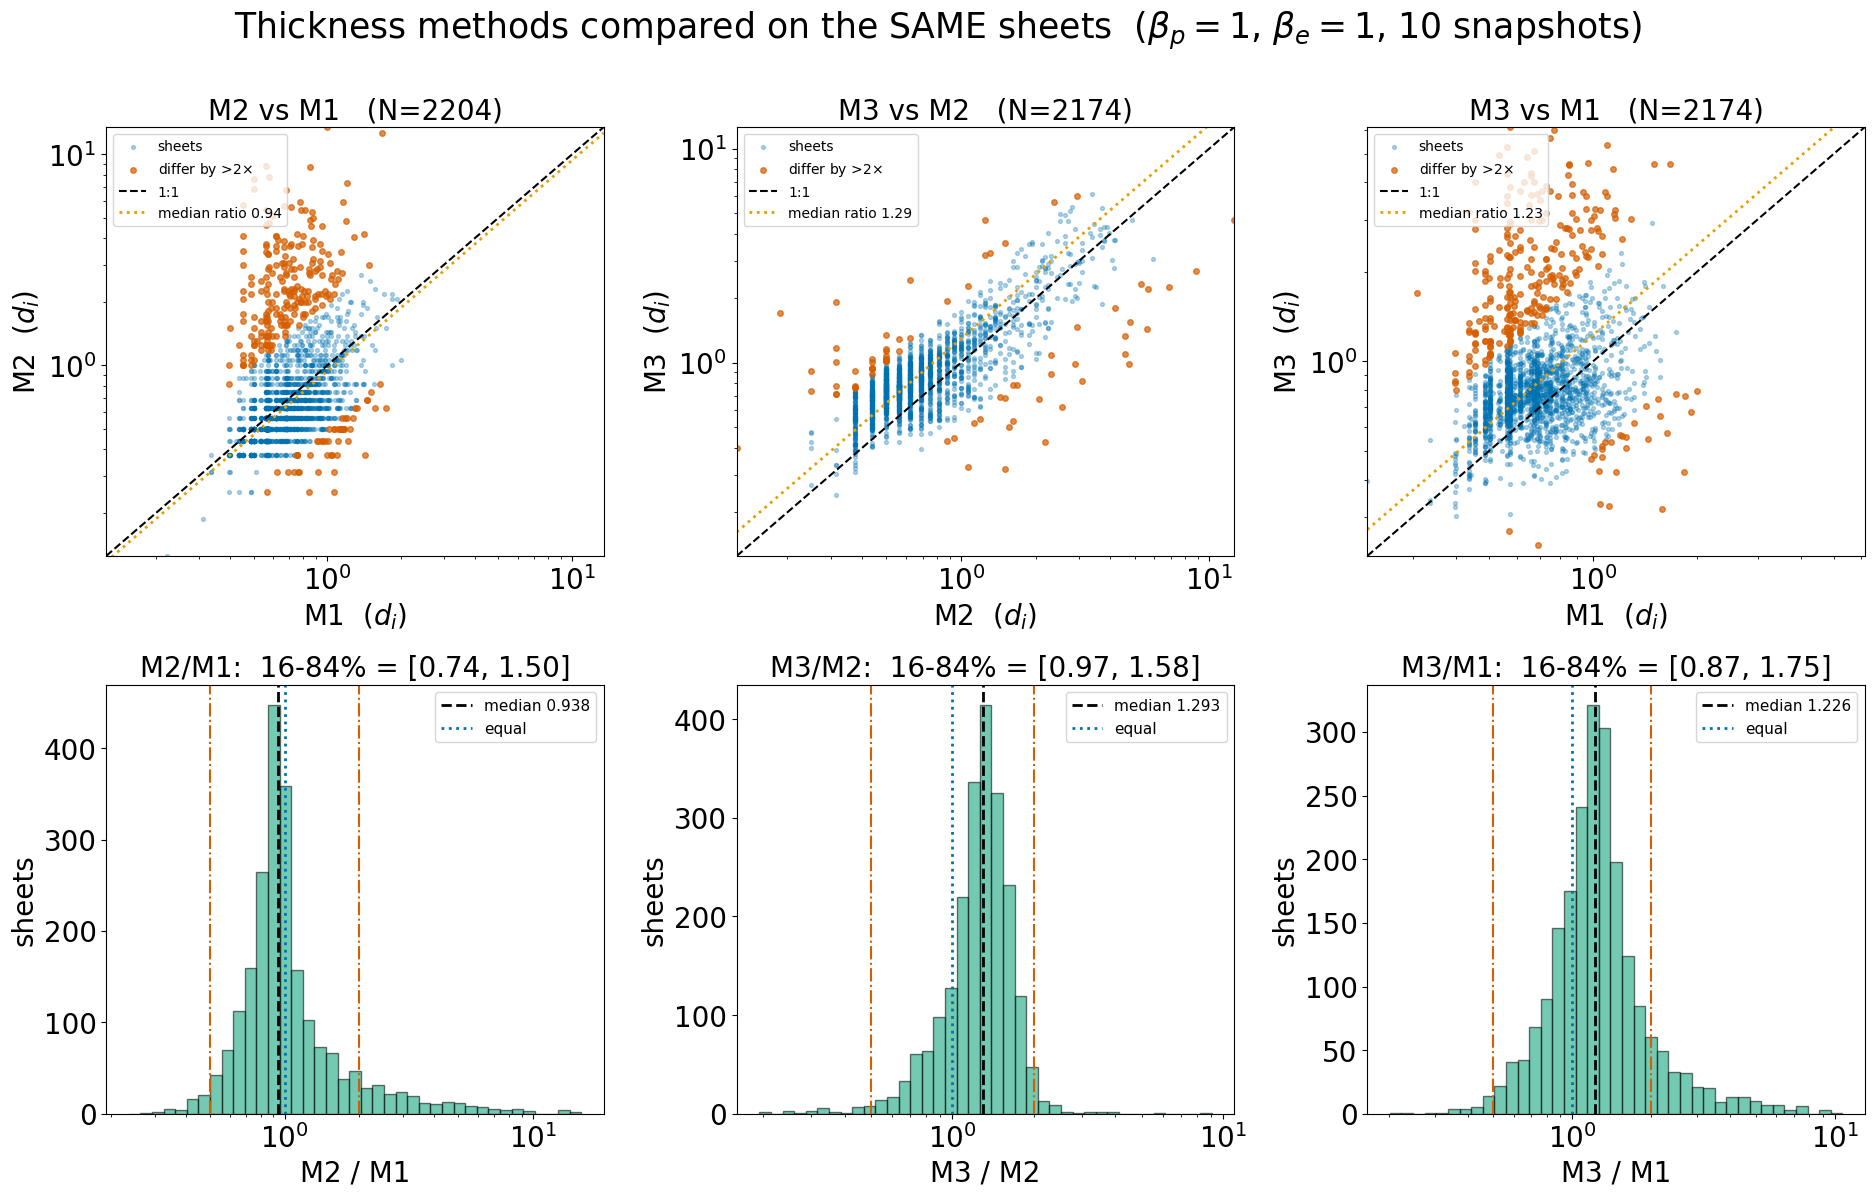

saved method_comparison_beta1.png

=== pairwise comparison (each pair judged on its own) ===

--- M2 vs M1 ---
  measured by both     : 2204 sheets
  median M2           : 0.625 d_i
  median M1           : 0.663 d_i
  ratio M2/M1         : median 0.938, 16-84% [0.740, 1.495]
  log correlation      : 0.3787
  agree within 10%     : 27.1%     within 25%: 60.5%
  differ by >2x        : 267 sheets (12.1%)
     on those sheets  : median M1 = 0.711, median M2 = 2.000 d_i

--- M3 vs M2 ---
  measured by both     : 2174 sheets
  median M3           : 0.790 d_i
  median M2           : 0.625 d_i
  ratio M3/M2         : median 1.293, 16-84% [0.968, 1.583]
  log correlation      : 0.7872
  agree within 10%     : 13.8%     within 25%: 38.0%
  differ by >2x        : 73 sheets (3.4%)
     on those sheets  : median M2 = 0.937, median M3 = 1.013 d_i

--- M3 vs M1 ---
  measured by both     : 2174 sheets
  median M3           : 0.790 d_i
  median M1           : 0.663 d_i
  ratio M3/M1         : median 1

In [6]:
# =====================================================================
#  M1 vs M2 vs M3, measured on THE SAME SHEETS
# ---------------------------------------------------------------------
#  The existing scripts filter each method's results separately, so a row of M1
#  values and a row of M3 values cannot be lined up sheet by sheet. This one
#  measures all three on every sheet and keeps them on a single row, with NaN
#  where a method could not produce an answer.
#
#  That pairing is what lets you ask the question that a pooled histogram cannot:
#  when one method says a sheet is 4 d_i thick, what do the other two say about
#  THAT sheet?
#
#  It matters for the M3 tail. M1 is the diameter of the largest circle that fits
#  inside the sheet, so it is bounded above by the sheet's actual width -- it
#  physically cannot report 4 d_i for a sheet that is not that wide. If the
#  sheets in M3's upper tail come back with ordinary M1 values, M3 has failed on
#  them, and the second component of that Gaussian mixture is an artefact rather
#  than a population of thick sheets.
#
#  Must already exist in your session:
#    iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets
# =====================================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({"font.size": 15})

# -----------------------------
# USER SETTINGS
# -----------------------------
BETA      = 1
TIMES     = list(range(200, 250, 5))
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)
cache_dir = str(CACHE / "filtered_cache_Jz")
out_fig   = str(RESULTS / f"method_comparison_beta{BETA}.png")
out_csv   = str(RESULTS / f"paired_thickness_beta{BETA}.csv")

PX_PER_DI    = 16.0
CONNECTIVITY = 2
dx = dy      = 0.0625

USE_SUBPIXEL_M1 = True     # True: measure M1 against the interpolated boundary, which
                           # removes the pixel quantisation (the empty bin at 0.6 d_i)
                           # and the parity bias. False: the classic 2*max(EDT).
DISAGREE_FACTOR = 2.0      # in each panel, highlight the sheets where THOSE TWO
                           # methods differ by more than this factor. Each pair is
                           # judged on its own -- the third method never enters.

SMOOTH_SIGMA = 3           # for the M2/M3 direction
MAX_LEN, SUBPIX_STEP, MARGIN_FRAC, MIN_HALF = 60, 0.5, 0.5, 6.0
MAX_FWHM_PX  = 100
BOUNDARY_SPACING = 0.25
REFINE_STEPS = (0.5, 0.25, 0.125, 0.0625)

N_WORKERS = min(len(TIMES), os.cpu_count() or 1)
THREADS_PER_WORKER = 1
FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

os.makedirs(cache_dir, exist_ok=True)


def _init_worker(n):
    if threadpool_limits is not None:
        threadpool_limits(limits=n)


# =====================================================================
#  M1 -- largest inscribed circle
# =====================================================================
def _crop(region):
    xs, ys = np.where(region)
    crop = region[xs.min():xs.max() + 1, ys.min():ys.max() + 1]
    return np.pad(crop, 2, constant_values=False)


def m1_classic(region):
    """2 x max of the distance transform. Quantised to sqrt(i^2+j^2) and biased
    high by ~half a pixel, but this is what your existing results used."""
    return 2.0 * float(ndi.distance_transform_edt(_crop(region)).max())


def m1_subpixel(region):
    """Same circle, but measured against the 0.5 level set rather than the pixel
    grid, and with the centre free to sit between pixels."""
    crop = _crop(region)
    pieces = measure.find_contours(crop.astype(float), 0.5)
    if not pieces:
        return np.nan
    pts = []
    for c in pieces:                             # densify so nearest-point ~ nearest-edge
        seg = np.diff(c, axis=0)
        for (x0, y0), (ddx, ddy) in zip(c[:-1], seg):
            n = max(1, int(np.ceil(np.hypot(ddx, ddy) / BOUNDARY_SPACING)))
            f = np.arange(n) / n
            pts.append(np.column_stack([x0 + f * ddx, y0 + f * ddy]))
        pts.append(c[-1][None, :])
    tree = cKDTree(np.vstack(pts))

    edt = ndi.distance_transform_edt(crop)
    best = np.array(np.unravel_index(int(np.argmax(edt)), edt.shape), float)
    best_d = float(tree.query(best[None, :])[0][0])
    nx, ny = crop.shape
    for step in REFINE_STEPS:
        moved = True
        while moved:
            moved = False
            off = np.array([[a, b] for a in (-step, 0.0, step)
                            for b in (-step, 0.0, step) if a or b])
            cand = best + off
            ij = np.rint(cand).astype(int)
            ok = ((ij[:, 0] >= 0) & (ij[:, 0] < nx) &
                  (ij[:, 1] >= 0) & (ij[:, 1] < ny))
            ok[ok] &= crop[ij[ok, 0], ij[ok, 1]]
            if not ok.any():
                break
            cand = cand[ok]
            d = tree.query(cand)[0]
            j = int(np.argmax(d))
            if d[j] > best_d + 1e-12:
                best, best_d, moved = cand[j], float(d[j]), True
    return 2.0 * best_d


# =====================================================================
#  M2 -- walk downhill to the mask edge, both ways
# =====================================================================
def walk_to_edge(mask, x0, y0, ux, uy, max_steps=1000):
    nx, ny = mask.shape
    xf, yf, s = float(x0), float(y0), 0
    while s < max_steps:
        xn, yn = xf + ux, yf + uy
        xi, yi = int(round(xn)), int(round(yn))
        if xi < 0 or yi < 0 or xi >= nx or yi >= ny or not mask[xi, yi]:
            break
        xf, yf, s = xn, yn, s + 1
    return np.hypot(xf - x0, yf - y0)


# =====================================================================
#  M3 -- fit a bell curve to the |J| profile along the same direction
# =====================================================================
def bell(t, A, mu, sigma, B):
    return A * np.exp(-(t - mu) ** 2 / (2 * sigma ** 2)) + B


def fwhm_along(J2, mask, xm, ym, ux, uy):
    nx, ny = mask.shape

    def edge(sx, sy):
        d = 0.0
        while d < MAX_LEN:
            dn = d + SUBPIX_STEP
            xi, yi = int(round(xm + sx * dn)) % nx, int(round(ym + sy * dn)) % ny
            if not mask[xi, yi]:
                break
            d = dn
        return d

    hf = min(MAX_LEN, max(MIN_HALF, edge(ux, uy) * (1 + MARGIN_FRAC)))
    hb = min(MAX_LEN, max(MIN_HALF, edge(-ux, -uy) * (1 + MARGIN_FRAC)))
    t = np.arange(-hb, hf + SUBPIX_STEP, SUBPIX_STEP)
    prof = ndi.map_coordinates(J2, np.vstack([xm + t * ux, ym + t * uy]),
                               order=1, mode="grid-wrap")
    if len(prof) < 4:
        return np.nan
    B0, A0 = float(prof.min()), float(prof.max() - prof.min())
    if A0 <= 0:
        return np.nan
    mu0 = float(t[np.argmax(prof)])
    above = np.where(prof >= B0 + 0.5 * A0)[0]
    s0 = (max(1.0, (t[above[-1]] - t[above[0]]) / 2.3548)
          if above.size >= 2 else max(2.0, (hf + hb) / 6.0))
    span = float(t.max() - t.min())
    s0 = min(s0, 0.99 * span)
    try:
        popt, _ = curve_fit(bell, t, prof, p0=[A0, mu0, s0, B0],
                            bounds=([0.0, t.min() - 1, 1e-3, -np.inf],
                                    [np.inf, t.max() + 1, span, np.inf]),
                            maxfev=10000)
    except (RuntimeError, ValueError):
        return np.nan
    w = 2 * np.sqrt(2 * np.log(2)) * abs(popt[2])
    return w if w <= MAX_FWHM_PX else np.nan


# =====================================================================
#  One snapshot -> one row per sheet: time, id, M1, M2, M3   (NaN = failed)
# =====================================================================
def extract(time):
    n_iter, Xi = FILTER_PARAMS[BETA]
    base = f"{base_root}/beta_p_{BETA}/beta_e_1/"
    with h5py.File(base + f"Bx_{sim_tag}_t{time}.h5", "r") as fx, \
         h5py.File(base + f"By_{sim_tag}_t{time}.h5", "r") as fy, \
         h5py.File(base + f"Bz_{sim_tag}_t{time}.h5", "r") as fz:
        Bx, By, Bz = fx["DS1"][:].T, fy["DS1"][:].T, fz["DS1"][:].T

    cached = f"{cache_dir}/filtered_beta_{BETA}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cached):
        d = np.load(cached)
        Bxf, Byf, Bzf = d["Bx"], d["By"], d["Bz"]
    else:
        Bxf, Byf, Bzf = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cached, Bx=Bxf, By=Byf, Bz=Bzf)

    J2 = np.abs(partial_x_fft(Byf, dy) - partial_y_fft(Bxf, dx))

    mask = np.zeros_like(J2)
    for sheet in detect_current_sheets(J2):
        for (i, j) in sheet:
            mask[i, j] = 1
    disk = morphology.disk(1)
    mask = morphology.binary_opening(mask, disk)
    mask = morphology.binary_closing(mask, disk)
    cleaned = morphology.remove_small_objects(mask.astype(bool), min_size=500)
    labeled = measure.label(cleaned, connectivity=CONNECTIVITY)

    J2s = gaussian_filter(J2, sigma=SMOOTH_SIGMA)
    gx, gy = np.gradient(J2s)

    rows = []
    for k in range(1, int(labeled.max()) + 1):
        region = (labeled == k)

        m1 = m1_subpixel(region) if USE_SUBPIXEL_M1 else m1_classic(region)

        xs_r, ys_r = np.where(region)
        pk = int(np.argmax(J2[region]))
        xm, ym = int(xs_r[pk]), int(ys_r[pk])
        g = np.array([gx[xm, ym], gy[xm, ym]])
        if np.allclose(g, 0):
            m2 = m3 = np.nan
        else:
            v = -g / np.linalg.norm(g)
            ux, uy = float(v[0]), float(v[1])
            m2 = (walk_to_edge(cleaned, xm, ym, ux, uy)
                  + walk_to_edge(cleaned, xm, ym, -ux, -uy))
            m2 = m2 if m2 > 0 else np.nan
            m3 = fwhm_along(J2, cleaned, xm, ym, ux, uy)

        rows.append([time, k, m1 / PX_PER_DI, m2 / PX_PER_DI, m3 / PX_PER_DI])
    return rows


COLUMNS = ["time", "sheet", "M1", "M2", "M3"]

# =====================================================================
if __name__ == "__main__":
    all_rows = []
    print(f"measuring {len(TIMES)} snapshots on {N_WORKERS} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=mp.get_context("fork"),
                             initializer=_init_worker,
                             initargs=(THREADS_PER_WORKER,)) as pool:
        jobs = {pool.submit(extract, t): t for t in TIMES}
        for job in as_completed(jobs):
            t = jobs[job]
            try:
                r = job.result(); all_rows += r
                print(f"  t={t}: {len(r)} sheets", flush=True)
            except FileNotFoundError:
                print(f"  t={t}: file missing, skipped", flush=True)

    if not all_rows:
        raise SystemExit("nothing measured -- check paths and TIMES")

    data = np.array(sorted(all_rows, key=lambda r: (r[0], r[1])), float)
    with open(out_csv, "w", newline="") as f:
        w = csv.writer(f); w.writerow(COLUMNS); w.writerows(data.tolist())
    print(f"\nsaved {out_csv}  ({len(data)} sheets)")

    M1, M2, M3 = data[:, 2], data[:, 3], data[:, 4]
    for nm, v in (("M1", M1), ("M2", M2), ("M3", M3)):
        ok = np.isfinite(v) & (v > 0)
        print(f"  {nm}: {ok.sum():5d} of {len(v)} sheets measured "
              f"({100*(1-ok.mean()):.1f}% missing), median {np.median(v[ok]):.3f} d_i")

    # ---- 2x3 figure: three scatters, three ratio histograms ----
    pairs = [("M1", M1, "M2", M2), ("M2", M2, "M3", M3), ("M1", M1, "M3", M3)]
    fig, ax = plt.subplots(2, 3, figsize=(19, 12))

    for c, (na, a, nb, b) in enumerate(pairs):
        # only these two methods decide which sheets appear and which stand out
        ok = np.isfinite(a) & np.isfinite(b) & (a > 0) & (b > 0)
        r = b[ok] / a[ok]
        odd = np.zeros_like(ok)
        odd[ok] = np.maximum(r, 1.0 / r) > DISAGREE_FACTOR

        # --- scatter ---
        s = ax[0, c]
        s.scatter(a[ok & ~odd], b[ok & ~odd], s=8, alpha=0.3, color="#0072B2",
                  label="sheets")
        if odd.any():
            s.scatter(a[odd], b[odd], s=16, alpha=0.7, color="#D55E00",
                      label=rf"differ by >{DISAGREE_FACTOR:g}$\times$")
        lim = [min(a[ok].min(), b[ok].min()), max(a[ok].max(), b[ok].max())]
        s.plot(lim, lim, "k--", lw=1.5, label="1:1")
        s.plot(lim, [np.median(r) * v for v in lim], ":", color="#E69F00", lw=2,
               label=f"median ratio {np.median(r):.2f}")
        s.set_xscale("log"); s.set_yscale("log")
        s.set_xlim(lim); s.set_ylim(lim)
        s.set_xlabel(rf"{na}  $(d_i)$"); s.set_ylabel(rf"{nb}  $(d_i)$")
        s.set_title(f"{nb} vs {na}   (N={int(ok.sum())})")
        s.legend(fontsize=10, loc="upper left")

        # --- ratio histogram ---
        h = ax[1, c]
        bins = np.logspace(np.log10(r.min()), np.log10(r.max()), 40)
        h.hist(r, bins=bins, color="#009E73", alpha=0.55, edgecolor="black")
        h.axvline(np.median(r), color="k", ls="--", lw=2,
                  label=f"median {np.median(r):.3f}")
        h.axvline(1.0, color="#0072B2", ls=":", lw=2, label="equal")
        for f in (DISAGREE_FACTOR, 1.0 / DISAGREE_FACTOR):
            h.axvline(f, color="#D55E00", ls="-.", lw=1.5)
        h.set_xscale("log")
        h.set_xlabel(rf"{nb} / {na}"); h.set_ylabel("sheets")
        h.set_title(f"{nb}/{na}:  16-84% = "
                    f"[{np.percentile(r,16):.2f}, {np.percentile(r,84):.2f}]")
        h.legend(fontsize=11)

    fig.suptitle(rf"Thickness methods compared on the SAME sheets  "
                 rf"($\beta_p={BETA}$, $\beta_e=1$, {len(TIMES)} snapshots)", y=1.00)
    fig.tight_layout()
    fig.savefig(out_fig, dpi=250, bbox_inches="tight")
    plt.show()
    print(f"saved {out_fig}")

    # ---- one block per pair; each uses only its own two methods ----
    print("\n=== pairwise comparison (each pair judged on its own) ===")
    for na, a, nb, b in pairs:
        ok = np.isfinite(a) & np.isfinite(b) & (a > 0) & (b > 0)
        if ok.sum() < 5:
            print(f"\n--- {nb} vs {na} ---   too few sheets measured by both")
            continue
        aa, bb = a[ok], b[ok]
        r = bb / aa
        odd = np.maximum(r, 1.0 / r) > DISAGREE_FACTOR
        print(f"\n--- {nb} vs {na} ---")
        print(f"  measured by both     : {int(ok.sum())} sheets")
        print(f"  median {nb:2s}           : {np.median(bb):.3f} d_i")
        print(f"  median {na:2s}           : {np.median(aa):.3f} d_i")
        print(f"  ratio {nb}/{na}         : median {np.median(r):.3f}, "
              f"16-84% [{np.percentile(r,16):.3f}, {np.percentile(r,84):.3f}]")
        print(f"  log correlation      : "
              f"{np.corrcoef(np.log(aa), np.log(bb))[0,1]:.4f}")
        print(f"  agree within 10%     : {100*np.mean(np.abs(r-1)<0.10):.1f}%"
              f"     within 25%: {100*np.mean(np.abs(r-1)<0.25):.1f}%")
        print(f"  differ by >{DISAGREE_FACTOR:g}x        : {int(odd.sum())} sheets "
              f"({100*odd.mean():.1f}%)")
        if odd.any():
            print(f"     on those sheets  : median {na} = {np.median(aa[odd]):.3f}, "
                  f"median {nb} = {np.median(bb[odd]):.3f} d_i")
    print("\nREAD IT LIKE THIS: if two methods disagree strongly on a set of sheets")
    print("while one of them stays at its usual value there, it is the OTHER one that")
    print("is being inflated on those sheets -- not a population of thicker sheets.")

measuring 10 snapshots on 10 workers ...
  t=225: 215 sheets
  t=235: 206 sheets
  t=240: 214 sheets
  t=210: 235 sheets
  t=245: 197 sheets
  t=230: 212 sheets
  t=220: 208 sheets
  t=205: 242 sheets
  t=215: 231 sheets
  t=200: 244 sheets

saved m1_paired_beta1.csv
2204 sheets measured both ways


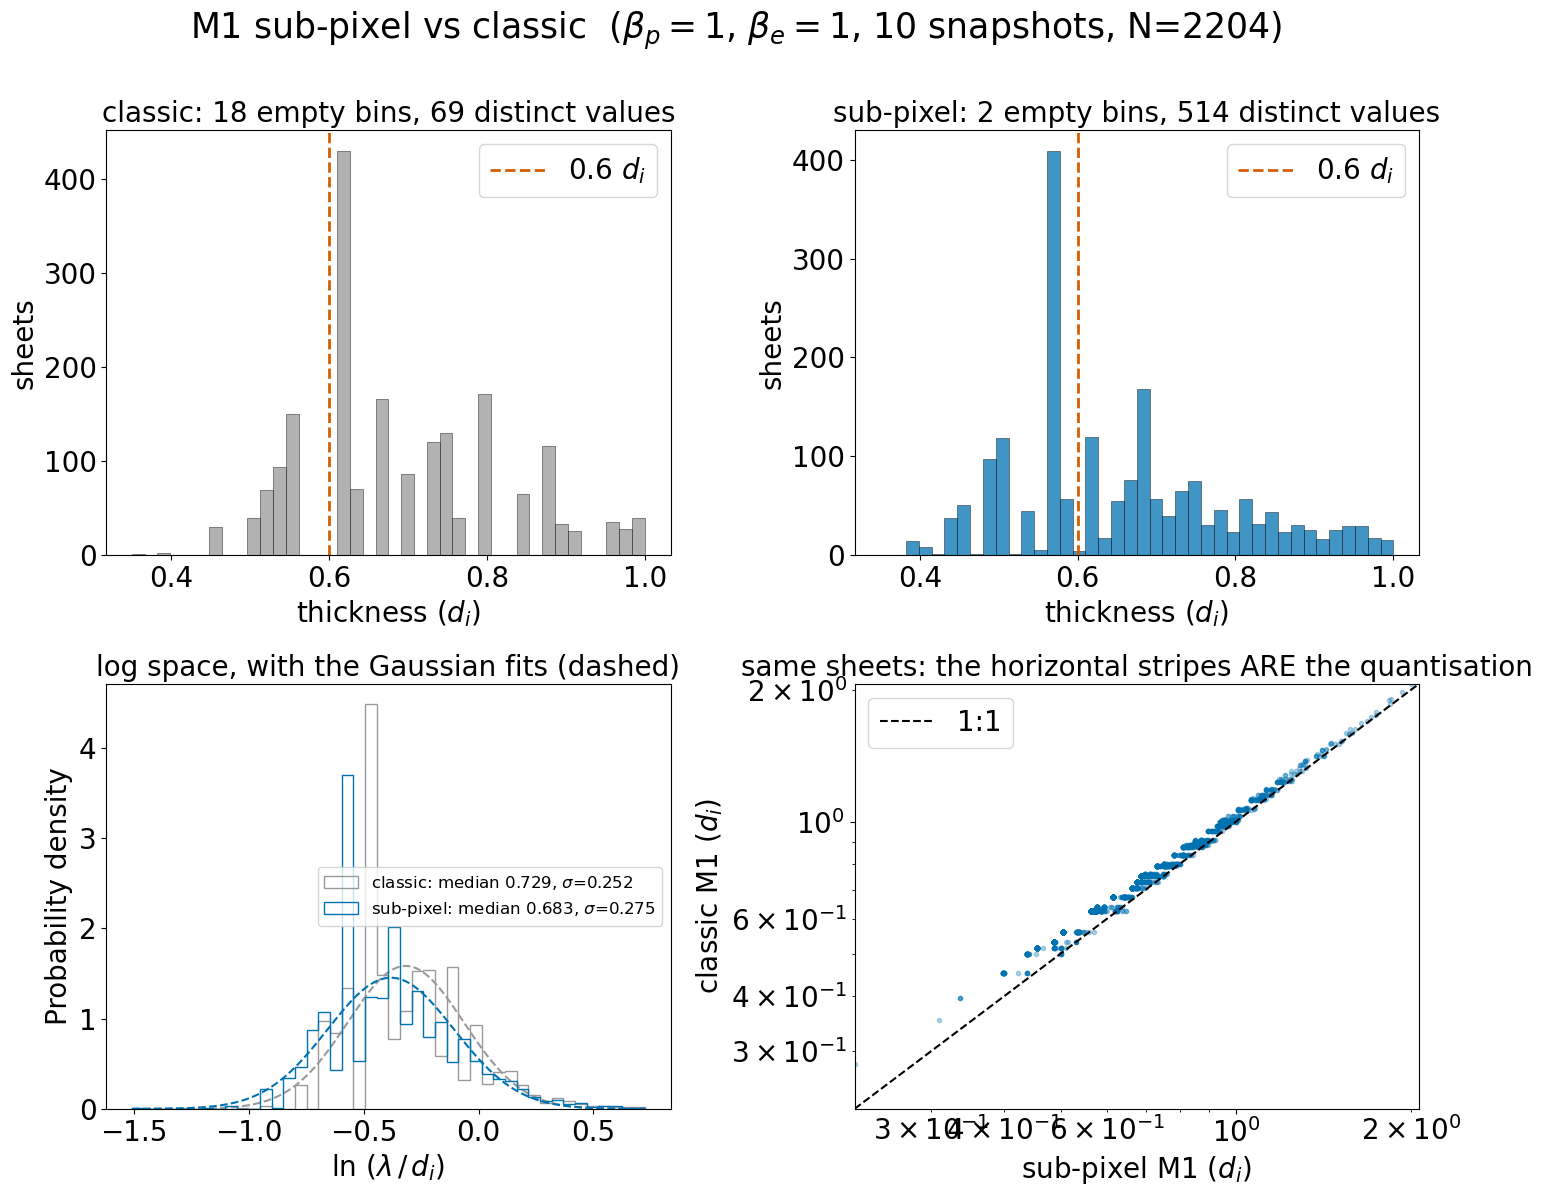

saved m1_subpixel_vs_classic_beta1.png

                  median    sigma     skew     kurt  distinct  empty
classic           0.7288   0.2520   +0.693   +0.645        69     18
sub-pixel         0.6830   0.2747   +0.601   +0.441       514      2

classic / sub-pixel: median 1.0671  (16-84% [1.0289, 1.1094])
  -> the classic version reads +6.7% high, i.e. +0.70 px on the median

'distinct' is how many different values the method can produce, and
'empty' how many bins it leaves empty over 0.35-1.0 d_i. Both should improve a lot.


In [7]:
# =====================================================================
#  M1 thickness, sub-pixel  --  and the classic version alongside it
# ---------------------------------------------------------------------
#  Both are the same measurement: the diameter of the largest circle that fits
#  inside the sheet. They differ in what they measure the circle against.
#
#    CLASSIC   2 * max(distance_transform_edt(mask))
#              The EDT measures to the nearest background PIXEL CENTRE, so:
#                * it can only return sqrt(i^2 + j^2) for integer offsets, giving
#                  a discrete, unevenly spaced ladder -- nothing is reachable
#                  between 0.559 and 0.625 d_i, which is why a histogram has an
#                  empty bin at 0.6 d_i even though real widths are continuous;
#                * it is biased high, rounding an axis-aligned sheet UP to the
#                  next even number of pixels (odd widths come out +1 px).
#
#    SUB-PIXEL Take the boundary at the 0.5 level set (interpolated between pixel
#              centres, so it sits on the real edge), and let the circle centre
#              sit anywhere, not just on a pixel. Checked against bars of exactly
#              known width: 7 -> 7.004, 9 -> 9.003, 11 -> 11.003, 13 -> 13.002 px,
#              where the classic version gave 8, 10, 12, 14.
#
#  Both are measured on EVERY sheet and kept paired, so the figure can show what
#  actually changed rather than comparing two different samples.
#
#  Must already exist in your session:
#    iterative_filtering3D, partial_x_fft, partial_y_fft, detect_current_sheets
# =====================================================================

import os
import csv
import numpy as np
import matplotlib.pyplot as plt
import h5py
from skimage import morphology, measure
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from scipy.stats import norm, skew, kurtosis
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None

plt.rcParams.update({"font.size": 16})

# -----------------------------
# USER SETTINGS
# -----------------------------
BETA      = 1
TIMES     = list(range(200, 250, 5))
sim_tag   = "ApJ"
base_root = str(DATA_ROOT)
cache_dir = str(CACHE / "filtered_cache_Jz")
out_fig   = str(RESULTS / f"m1_subpixel_vs_classic_beta{BETA}.png")
out_csv   = str(RESULTS / f"m1_paired_beta{BETA}.csv")

PX_PER_DI    = 16.0
CONNECTIVITY = 2
dx = dy      = 0.0625

BOUNDARY_SPACING = 0.25                     # densify the boundary to this spacing (px)
REFINE_STEPS = (0.5, 0.25, 0.125, 0.0625)   # local search for the circle centre
GAP_RANGE    = (0.35, 1.00)                 # linear-histogram window for the gap check
GAP_BINS     = 40

N_WORKERS = min(len(TIMES), os.cpu_count() or 1)
THREADS_PER_WORKER = 1
FILTER_PARAMS = {0.0625: (3, 2.0), 0.25: (3, 2.3), 1: (3, 2.5), 4: (3, 2.7), 16: (3, 3.0)}

os.makedirs(cache_dir, exist_ok=True)


def _init_worker(n):
    if threadpool_limits is not None:
        threadpool_limits(limits=n)


# =====================================================================
#  the two measurements
# =====================================================================
def crop_with_border(region):
    """Cut the sheet out with a 2-pixel empty border, so there is always an
    'outside' for the distance to be measured to."""
    xs, ys = np.where(region)
    crop = region[xs.min():xs.max() + 1, ys.min():ys.max() + 1]
    return np.pad(crop, 2, constant_values=False)


def m1_classic(crop):
    return 2.0 * float(ndi.distance_transform_edt(crop).max())


def boundary_cloud(crop):
    """The sheet edge as a dense cloud of sub-pixel points.

    find_contours traces the 0.5 level set, interpolating between pixel centres,
    so its vertices lie on the real edge. Its vertices come out about a pixel
    apart, so we fill in along each segment: otherwise the nearest VERTEX can be
    noticeably further away than the nearest point of the edge itself.
    """
    pieces = measure.find_contours(crop.astype(float), 0.5)
    if not pieces:
        return None
    pts = []
    for c in pieces:
        for (x0, y0), (ddx, ddy) in zip(c[:-1], np.diff(c, axis=0)):
            n = max(1, int(np.ceil(np.hypot(ddx, ddy) / BOUNDARY_SPACING)))
            f = np.arange(n) / n
            pts.append(np.column_stack([x0 + f * ddx, y0 + f * ddy]))
        pts.append(c[-1][None, :])
    return np.vstack(pts)


def m1_subpixel(crop):
    """Largest inscribed circle, measured against the sub-pixel boundary, with the
    centre free to sit between pixels. Start from the classic best pixel, then
    hill-climb on ever finer steps."""
    cloud = boundary_cloud(crop)
    if cloud is None or len(cloud) < 3:
        return np.nan
    tree = cKDTree(cloud)

    edt = ndi.distance_transform_edt(crop)
    best = np.array(np.unravel_index(int(np.argmax(edt)), edt.shape), float)
    best_d = float(tree.query(best[None, :])[0][0])

    nx, ny = crop.shape
    for step in REFINE_STEPS:
        moved = True
        while moved:
            moved = False
            off = np.array([[a, b] for a in (-step, 0.0, step)
                            for b in (-step, 0.0, step) if a or b])
            cand = best + off
            ij = np.rint(cand).astype(int)
            inside = ((ij[:, 0] >= 0) & (ij[:, 0] < nx) &
                      (ij[:, 1] >= 0) & (ij[:, 1] < ny))
            inside[inside] &= crop[ij[inside, 0], ij[inside, 1]]
            if not inside.any():
                break
            cand = cand[inside]
            d = tree.query(cand)[0]
            j = int(np.argmax(d))
            if d[j] > best_d + 1e-12:
                best, best_d, moved = cand[j], float(d[j]), True
    return 2.0 * best_d


# =====================================================================
#  one snapshot -> one row per sheet: time, id, classic, sub-pixel
# =====================================================================
def extract(time):
    n_iter, Xi = FILTER_PARAMS[BETA]
    base = f"{base_root}/beta_p_{BETA}/beta_e_1/"
    with h5py.File(base + f"Bx_{sim_tag}_t{time}.h5", "r") as fx, \
         h5py.File(base + f"By_{sim_tag}_t{time}.h5", "r") as fy, \
         h5py.File(base + f"Bz_{sim_tag}_t{time}.h5", "r") as fz:
        Bx, By, Bz = fx["DS1"][:].T, fy["DS1"][:].T, fz["DS1"][:].T

    cached = f"{cache_dir}/filtered_beta_{BETA}_t{time}_iter{n_iter}_Xi{Xi}.npz"
    if os.path.exists(cached):
        d = np.load(cached)
        Bxf, Byf, Bzf = d["Bx"], d["By"], d["Bz"]
    else:
        Bxf, Byf, Bzf = iterative_filtering3D(Bx, By, Bz, n_iter, Xi=Xi)
        np.savez_compressed(cached, Bx=Bxf, By=Byf, Bz=Bzf)

    J2 = np.abs(partial_x_fft(Byf, dy) - partial_y_fft(Bxf, dx))

    mask = np.zeros_like(J2)
    for sheet in detect_current_sheets(J2):
        for (i, j) in sheet:
            mask[i, j] = 1
    disk = morphology.disk(1)
    mask = morphology.binary_opening(mask, disk)
    mask = morphology.binary_closing(mask, disk)
    cleaned = morphology.remove_small_objects(mask.astype(bool), min_size=500)
    labeled = measure.label(cleaned, connectivity=CONNECTIVITY)

    rows = []
    for k in range(1, int(labeled.max()) + 1):
        crop = crop_with_border(labeled == k)          # crop ONCE, use for both
        rows.append([time, k, m1_classic(crop) / PX_PER_DI,
                     m1_subpixel(crop) / PX_PER_DI])
    return rows


COLUMNS = ["time", "sheet", "M1_classic", "M1_subpixel"]


def fit_log_gaussian(x):
    """Gaussian fitted to ln(x) -- closed-form maximum likelihood, so it does not
    depend on the binning. exp(mu) is the median; sigma is the log-normal shape."""
    lg = np.log(x)
    mu, sd = norm.fit(lg)
    return {"mu": float(mu), "sigma": float(sd), "median": float(np.exp(mu)),
            "skew": float(skew(lg)), "kurt": float(kurtosis(lg)), "n": int(x.size),
            "logs": lg}


# =====================================================================
if __name__ == "__main__":
    all_rows = []
    print(f"measuring {len(TIMES)} snapshots on {N_WORKERS} workers ...", flush=True)
    with ProcessPoolExecutor(max_workers=N_WORKERS, mp_context=mp.get_context("fork"),
                             initializer=_init_worker,
                             initargs=(THREADS_PER_WORKER,)) as pool:
        jobs = {pool.submit(extract, t): t for t in TIMES}
        for job in as_completed(jobs):
            t = jobs[job]
            try:
                r = job.result(); all_rows += r
                print(f"  t={t}: {len(r)} sheets", flush=True)
            except FileNotFoundError:
                print(f"  t={t}: file missing, skipped", flush=True)

    if not all_rows:
        raise SystemExit("nothing measured -- check paths and TIMES")

    data = np.array(sorted(all_rows, key=lambda r: (r[0], r[1])), float)
    with open(out_csv, "w", newline="") as f:
        w = csv.writer(f); w.writerow(COLUMNS); w.writerows(data.tolist())
    print(f"\nsaved {out_csv}")

    ok = np.isfinite(data[:, 2]) & np.isfinite(data[:, 3]) & (data[:, 2] > 0) & (data[:, 3] > 0)
    classic, sub = data[ok, 2], data[ok, 3]
    print(f"{ok.sum()} sheets measured both ways")

    fc, fs = fit_log_gaussian(classic), fit_log_gaussian(sub)

    # -------- figure --------
    fig, ax = plt.subplots(2, 2, figsize=(15, 12))
    C_OLD, C_NEW = "#999999", "#0072B2"

    # (a) and (b): linear histograms over the gap window
    edges = np.linspace(*GAP_RANGE, GAP_BINS + 1)
    for j, (nm, v, col) in enumerate((("classic", classic, C_OLD),
                                      ("sub-pixel", sub, C_NEW))):
        a = ax[0, j]
        h, _ = np.histogram(v, bins=edges)
        a.bar(0.5 * (edges[1:] + edges[:-1]), h, width=np.diff(edges),
              color=col, alpha=0.75, edgecolor="black", linewidth=0.4)
        a.axvline(0.6, color="#D55E00", ls="--", lw=2, label=r"0.6 $d_i$")
        a.set_xlabel(r"thickness $(d_i)$"); a.set_ylabel("sheets")
        a.set_title(f"{nm}: {int((h == 0).sum())} empty bins, "
                    f"{len(np.unique(np.round(v, 6)))} distinct values")
        a.legend()

    # (c) log space, both fits overlaid
    a = ax[1, 0]
    lo = min(fc["logs"].min(), fs["logs"].min())
    hi = max(fc["logs"].max(), fs["logs"].max())
    lbins = np.linspace(lo, hi, 45)
    grid = np.linspace(lo, hi, 400)
    for nm, f, col in (("classic", fc, C_OLD), ("sub-pixel", fs, C_NEW)):
        a.hist(f["logs"], bins=lbins, density=True, histtype="step", lw=2.5, color=col,
               label=f"{nm}: median {f['median']:.3f}, $\\sigma$={f['sigma']:.3f}")
        a.plot(grid, norm.pdf(grid, f["mu"], f["sigma"]), color=col, lw=1.5, ls="--")
    a.set_xlabel(r"$\ln\,(\lambda\,/\,d_i)$"); a.set_ylabel("Probability density")
    a.set_title("log space, with the Gaussian fits (dashed)")
    a.legend(fontsize=12)

    # (d) the same sheets, one against the other
    a = ax[1, 1]
    a.scatter(sub, classic, s=9, alpha=0.3, color=C_NEW)
    lim = [min(sub.min(), classic.min()), max(sub.max(), classic.max())]
    a.plot(lim, lim, "k--", lw=1.5, label="1:1")
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(lim); a.set_ylim(lim)
    a.set_xlabel(r"sub-pixel M1 $(d_i)$"); a.set_ylabel(r"classic M1 $(d_i)$")
    a.set_title("same sheets: the horizontal stripes ARE the quantisation")
    a.legend()

    fig.suptitle(rf"M1 sub-pixel vs classic  ($\beta_p={BETA}$, $\beta_e=1$, "
                 rf"{len(TIMES)} snapshots, N={int(ok.sum())})", y=1.00)
    fig.tight_layout()
    fig.savefig(out_fig, dpi=250, bbox_inches="tight")
    plt.show()
    print(f"saved {out_fig}")

    # -------- numbers --------
    print(f"\n{'':14s}{'median':>10s}{'sigma':>9s}{'skew':>9s}{'kurt':>9s}"
          f"{'distinct':>10s}{'empty':>7s}")
    for nm, f, v in (("classic", fc, classic), ("sub-pixel", fs, sub)):
        h, _ = np.histogram(v, bins=edges)
        print(f"{nm:14s}{f['median']:>10.4f}{f['sigma']:>9.4f}{f['skew']:>+9.3f}"
              f"{f['kurt']:>+9.3f}{len(np.unique(np.round(v,6))):>10d}"
              f"{int((h==0).sum()):>7d}")
    r = classic / sub
    print(f"\nclassic / sub-pixel: median {np.median(r):.4f}  "
          f"(16-84% [{np.percentile(r,16):.4f}, {np.percentile(r,84):.4f}])")
    print(f"  -> the classic version reads {100*(np.median(r)-1):+.1f}% high, i.e. "
          f"{PX_PER_DI*(np.median(classic)-np.median(sub)):+.2f} px on the median")
    print("\n'distinct' is how many different values the method can produce, and")
    print("'empty' how many bins it leaves empty over "
          f"{GAP_RANGE[0]}-{GAP_RANGE[1]} d_i. Both should improve a lot.")